# Women's sweaters & cardigans across brands — Descriptive analysis

**Main question:** Is a brand's price level / segment related to its use of natural fibres (wool & cashmere in particular), and how much do fast-fashion brands rely on synthetics?

**Data:** women's sweaters and cardigans scraped from US online stores (USD), snapshot 22–26 Oct 2026, in three linked tables:

| File | One row per | Key | Content |
|---|---|---|---|
| `models.csv` | model (style) | `model_key` | price range over colours, main-fabric composition, origin |
| `variants.csv` | colour of a model | `variant_key` → `model_key` | full page fields: price, composition, care, origin, sustainability, description |
| `fibres.csv` | fibre of a variant's main fabric | `variant_key` | long format: fibre name and % |

| Segment (planned) | Brands |
|---|---|
| Fast fashion | Zara, Mango, H&M, Bershka |
| Ultra-fast fashion | SHEIN |
| Mid / premium | UNIQLO, COS, & Other Stories, Massimo Dutti |

**Unit of analysis = model.** The number of colours collected per model differs a lot by brand (Zara ≈ 1, UNIQLO ≈ 5), so variant-level statistics would over-weight brands with many colours. Variant-level fields (care, origin, sustainability) are aggregated to the model.

**Part 1** checks structure, scope, missing and invalid values and cleans the data. **Part 2** describes price, fibre composition, price × fibre, origin, sustainability claims and care. Section 14 summarises findings and limitations.

## 0. Setup

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

DATA_DIR = Path("./dataset/")   # folder holding models.csv, variants.csv, fibres.csv
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

In [2]:
# Chart style: light surface, recessive grid; colour only where it encodes something.
SURFACE, GRID, INK, INK2, NEUTRAL = "#fcfcfb", "#e1e0d9", "#0b0b0b", "#52514e", "#898781"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"  # fixed categorical order (CVD-checked)
SEG_COLORS = {"Fast fashion": BLUE, "Mid/premium": ORANGE}
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#eef4fc", BLUE, "#0d3a6e"])  # magnitude: one hue
DIV = LinearSegmentedColormap.from_list("div", [ORANGE, "#efeeea", BLUE])         # polarity: two hues, grey middle

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11.5, "axes.titlelocation": "left",
    "font.size": 9.5, "legend.frameon": False, "figure.dpi": 110,
})


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def usd_axis(ax, axis="x", ticks=(10, 20, 30, 50, 100, 200, 300, 500, 1000)):
    target = ax.xaxis if axis == "x" else ax.yaxis
    target.set_major_locator(mticker.FixedLocator(ticks))
    target.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    target.set_minor_locator(mticker.NullLocator())


def heatmap(ax, table, fmt=lambda v: f"{v:.0f}", vmin=0, vmax=100, cmap=SEQ, skip_zero=False):
    ax.imshow(table.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.iat[i, j]
            if pd.isna(v) or (skip_zero and v == 0):
                continue
            ax.text(j, i, fmt(v), ha="center", va="center", fontsize=8.3,
                    color="white" if abs(v) > 0.55 * vmax else INK)
    ax.set_xticks(np.arange(-.5, table.shape[1]), minor=True)
    ax.set_yticks(np.arange(-.5, table.shape[0]), minor=True)
    ax.grid(False)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)


def stacked_bars(share, colors, ylabels, notes=None, title="", xlabel="% of models", label_min=8, fname=None):
    # share: rows = bars (top to bottom), columns = categories in fixed order, values in % (rows sum to 100)
    notes = notes or {}
    fig, ax = plt.subplots(figsize=(9.5, 0.52 * len(share) + 1.7))
    y = np.arange(len(share))[::-1]
    left = np.zeros(len(share))
    for cat in share.columns:
        vals = share[cat].fillna(0).to_numpy(dtype=float)
        ax.barh(y, vals, left=left, color=colors[cat], edgecolor=SURFACE, linewidth=2, height=0.62, label=cat)
        for yi, l, v in zip(y, left, vals):
            if v >= label_min:
                ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=8.3,
                        color="white" if colors[cat] == BLUE else INK)
        left += vals
    for idx, text in notes.items():
        ax.text(1, y[list(share.index).index(idx)], text, va="center", ha="left", color=INK2, style="italic", fontsize=8.8)
    ax.set_yticks(y, ylabels)
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.legend(ncol=len(share.columns), loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8.5,
              handlelength=1.2, columnspacing=1.2)
    ax.set_title(title, pad=26)
    fig.tight_layout()
    if fname:
        savefig(fig, fname)
    return fig, ax


def bh(pvals):
    # Benjamini-Hochberg adjusted p-values
    p = np.asarray(pvals, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order] * n / (np.arange(n) + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.minimum(q, 1)
    return out


def tidy(t, digits=3):
    # round for display; p-values in scientific notation, counts as integers
    t = t.copy()
    pcols = [c for c in t.columns if c in ("p", "p_BH") or str(c).endswith("_p")]
    ncols = [c for c in t.columns if str(c) == "n" or str(c).startswith("n_")]
    for c in t.columns:
        if c in pcols:
            t[c] = t[c].map(lambda v: "" if pd.isna(v) else (f"{v:.1e}" if v < 0.001 else f"{v:.3f}"))
        elif c in ncols:
            t[c] = t[c].astype("Int64")
        elif pd.api.types.is_float_dtype(t[c]):
            t[c] = t[c].round(digits)
    return t


def mann_whitney(a, b):
    # two-sided Mann-Whitney U with rank-biserial r (positive -> a tends to be larger)
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    return pd.Series({"n_a": len(a), "n_b": len(b), "median_a": a.median(), "median_b": b.median(),
                      "U": u, "p": p, "r_rb": 2 * u / (len(a) * len(b)) - 1})

---
# Part 1 — Data quality and cleaning

### 1. Structure

In [3]:
models_raw = pd.read_csv(DATA_DIR / "models.csv", encoding="utf-8-sig")
variants_raw = pd.read_csv(DATA_DIR / "variants.csv", encoding="utf-8-sig", low_memory=False)
fibres_raw = pd.read_csv(DATA_DIR / "fibres.csv", encoding="utf-8-sig")

for name, t, key in [("models", models_raw, "model_key"), ("variants", variants_raw, "variant_key"), ("fibres", fibres_raw, None)]:
    dtypes = t.dtypes.astype(str).value_counts().to_dict()
    dup = t[key].duplicated().sum() if key else t.duplicated(["variant_key", "fibre", "fibre_names"]).sum()
    print(f"{name:9s} shape={t.shape}  dtypes={dtypes}  duplicated keys={dup}")

print("\nvariants -> models: every model_key exists:", variants_raw["model_key"].isin(models_raw["model_key"]).all(),
      "| models without a variant:", (~models_raw["model_key"].isin(variants_raw["model_key"])).sum())
print("fibres -> variants: every variant_key exists:", fibres_raw["variant_key"].isin(variants_raw["variant_key"]).all())
print("country:", variants_raw["country"].dropna().unique().tolist(), "| currency:", variants_raw["currency"].dropna().unique().tolist())

models    shape=(1598, 35)  dtypes={'float64': 19, 'object': 12, 'int64': 2, 'bool': 2}  duplicated keys=0
variants  shape=(3270, 58)  dtypes={'object': 35, 'float64': 22, 'bool': 1}  duplicated keys=0
fibres    shape=(8480, 7)  dtypes={'object': 6, 'float64': 1}  duplicated keys=0

variants -> models: every model_key exists: True | models without a variant: 0
fibres -> variants: every variant_key exists: True
country: ['US'] | currency: ['USD']


In [4]:
COLUMN_GROUPS = {
    "identification": ["variant_key", "model_key", "brand", "product_ref", "model_id", "color_id", "product_url"],
    "product": ["product_name", "category", "subcategory", "color", "description_raw", "fit", "weight_g"],
    "price": ["currency", "price_current", "price_original", "on_sale", "discount_pct", "price_source"],
    "composition": ["composition_raw", "composition_outer_raw", "composition_parse_status", "other_fibres"]
                   + [c for c in variants_raw.columns if c.endswith("_pct") and c != "discount_pct"],
    "origin / care / sustainability": ["origin_raw", "origin_country", "supplier_factory", "care_raw", "sustainability_raw"],
    "collection metadata": ["country", "collected_at", "collected_date", "collection_status", "warnings", "brand_key",
                            "source_mode", "variant_source", "source_file", "collected_at_source", "requested_url", "source_csv"],
}
pd.DataFrame({"n_columns": {k: len(v) for k, v in COLUMN_GROUPS.items()},
              "columns (variants.csv)": {k: ", ".join(v) for k, v in COLUMN_GROUPS.items()}})

,n_columns,columns (variants.csv)
identification,7,"variant_key, model_key, brand, product_ref, model_id, color_id, product_url"
product,7,"product_name, category, subcategory, color, description_raw, fit, weight_g"
price,6,"currency, price_current, price_original, on_sale, discount_pct, price_source"
composition,19,"composition_raw, composition_outer_raw, composition_parse_status, other_fibres, cotton..."
origin / care / sustainability,5,"origin_raw, origin_country, supplier_factory, care_raw, sustainability_raw"
collection metadata,12,"country, collected_at, collected_date, collection_status, warnings, brand_key, source_..."


In [5]:
# rows per brand, colours per model, collection mode and dates
per_brand = models_raw.groupby("brand").agg(models=("model_key", "size"), colours_mean=("n_colours", "mean"),
                                            colours_max=("n_colours", "max"))
per_brand["variants"] = variants_raw["brand"].value_counts()
per_brand["source_mode"] = variants_raw.groupby("brand")["source_mode"].agg(lambda s: ", ".join(sorted(s.dropna().unique())))
per_brand["first_day"] = variants_raw.groupby("brand")["collected_date"].min()
per_brand["last_day"] = variants_raw.groupby("brand")["collected_date"].max()
per_brand["variant_status"] = variants_raw.groupby("brand")["collection_status"].agg(lambda s: s.value_counts().to_dict())
per_brand.sort_values("models", ascending=False).round(2)

,models,colours_mean,colours_max,variants,source_mode,first_day,last_day,variant_status
brand,,,,,,,,
H&M,457,2.84,37,1299,saved_html,2026-10-25,2026-10-25,{'complete': 1299}
Mango,409,1.38,6,566,browser,2026-10-22,2026-10-26,{'complete': 566}
Zara,304,1.01,2,306,browser,2026-10-22,2026-10-26,"{'complete': 284, 'partial': 22}"
Massimo Dutti,152,1.91,10,290,browser,2026-10-24,2026-10-26,"{'complete': 287, 'partial': 3}"
& Other Stories,80,2.89,17,231,saved_html,2026-10-26,2026-10-26,"{'complete': 229, 'partial': 2}"
COS,68,1.91,6,130,saved_html,2026-10-23,2026-10-23,"{'complete': 129, 'partial': 1}"
Bershka,65,2.23,8,145,browser,2026-10-26,2026-10-26,"{'complete': 143, 'partial': 2}"
UNIQLO,63,4.81,22,303,saved_html,2026-10-24,2026-10-26,{'complete': 303}


In [6]:
models_raw.sample(2, random_state=1).T

,75,1282
model_key,cos:1351534,uniqlo:E487939-000
brand,COS,UNIQLO
brand_key,cos,uniqlo
model_id,1351534,E487939-000
product_name,Jersey Cardigan Top,Souffle Yarn Polo Sweater
category,cardigan,sweater
subcategory,cardigans,sweaters & cardigans
n_colours,3,5
n_colours_parsed,3,5
price_min,79.0,39.9


### 2. Scope check

Scope: women's sweaters and cardigans (vests, jackets, dresses and knit tops out of scope). Checks: planned vs observed brands,
knit tops that came in through category pages, and borderline items. The filter is applied to models and carried to variants and fibres.

In [7]:
SEGMENT = {"Zara": "Fast fashion", "Mango": "Fast fashion", "H&M": "Fast fashion", "Bershka": "Fast fashion",
           "SHEIN": "Ultra-fast fashion",
           "UNIQLO": "Mid/premium", "COS": "Mid/premium", "& Other Stories": "Mid/premium", "Massimo Dutti": "Mid/premium"}
pd.DataFrame({"segment": SEGMENT, "models": models_raw["brand"].value_counts()}).fillna({"models": 0}) \
  .astype({"models": int}).sort_values(["segment", "models"], ascending=[True, False])

,segment,models
H&M,Fast fashion,457
Mango,Fast fashion,409
Zara,Fast fashion,304
Bershka,Fast fashion,65
Massimo Dutti,Mid/premium,152
& Other Stories,Mid/premium,80
COS,Mid/premium,68
UNIQLO,Mid/premium,63
SHEIN,Ultra-fast fashion,0


In [8]:
name = models_raw["product_name"].fillna("").str.lower()
knit_top = name.str.contains(r"\b(?:top|t-shirt|shirt)\b") & ~name.str.contains(r"sweater|jumper|cardigan")
cape = name.str.contains(r"\bcape|poncho")
print("models without a name:", models_raw["product_name"].isna().sum())
print("knit tops (out of scope):", knit_top.sum(), models_raw.loc[knit_top, "brand"].value_counts().to_dict())
display(models_raw.loc[knit_top, ["brand", "product_name", "subcategory", "price_median"]].head(10))
print("capes / ponchos (kept, flagged):", cape.sum())
models_raw.loc[cape, ["brand", "product_name", "category", "price_median"]]

models without a name: 0
knit tops (out of scope): 36 {'H&M': 34, 'Mango': 2}


,brand,product_name,subcategory,price_median
332,H&M,Bead-Embellished Peplum Top,sweaters,39.99
340,H&M,Bouclé-Knit T-Shirt,sweaters,39.99
342,H&M,Boxy Fine-Knit Top,sweaters,39.99
344,H&M,Boxy-Style Knit Top,sweaters,39.99
349,H&M,Cable-Knit Polo Shirt,sweaters,39.99
377,H&M,Fine-Knit Boat-Neck Top,sweaters,39.99
383,H&M,Fine-Knit Mock Turtleneck Top,sweaters,44.99
385,H&M,Fine-Knit Polo Shirt,sweaters,22.99
386,H&M,Fine-Knit Polo Shirt,sweaters,42.99
387,H&M,Fine-Knit Polo Shirt,sweaters,27.99


capes / ponchos (kept, flagged): 7


,brand,product_name,category,price_median
108,COS,Draped Pure Cashmere Cape Sweater,sweater,449.00
414,H&M,Knit Mock Turtleneck Cape,sweater,39.99
715,Mango,Asymmetrical knitted cape,sweater,59.99
856,Mango,Plain knit cape,sweater,79.99
1075,Massimo Dutti,100% wool knit cape with button detail,sweater,220.00
1101,Massimo Dutti,Crochet knit cape,sweater,290.00
1541,Zara,SHORT KNIT CAPE SWEATER,sweater,45.90


In [9]:
models = models_raw.loc[~knit_top].copy()
models["is_cape"] = cape.loc[models.index]
models["segment"] = models["brand"].map(SEGMENT)
variants = variants_raw[variants_raw["model_key"].isin(models["model_key"])].copy()
fibres = fibres_raw[fibres_raw["variant_key"].isin(variants["variant_key"])].copy()
print(f"in scope: {len(models)} models, {len(variants)} variants, {len(fibres)} fibre rows")
pd.crosstab(models["brand"], models["category"], margins=True)

in scope: 1562 models, 3169 variants, 8203 fibre rows


category,cardigan,sweater,All
brand,,,
& Other Stories,41,39,80
Bershka,14,51,65
COS,31,37,68
H&M,195,228,423
Mango,101,306,407
Massimo Dutti,52,100,152
UNIQLO,15,48,63
Zara,122,182,304
All,571,991,1562


### 3. Missing Values

Missingness is almost entirely **brand-specific**: it reflects what each site shows and what each scraper extracted.
Details (care, origin, sustainability) live at the variant level, so coverage is shown per variant.

In [10]:
na = models.isna().sum()
display(pd.DataFrame({"n_missing": na, "pct": (na / len(models) * 100).round(1)}).query("n_missing > 0")
        .sort_values("n_missing", ascending=False).rename_axis("models.csv"))
na = variants.isna().sum()
pd.DataFrame({"n_missing": na, "pct": (na / len(variants) * 100).round(1)}).query("n_missing > 0") \
  .sort_values("n_missing", ascending=False).rename_axis("variants.csv")

,n_missing,pct
models.csv,,
other_fibres,1549,99.2
max_discount_pct,1448,92.7
origin_country,878,56.2
subcategory,449,28.7
composition_outer_raw,110,7.0
cotton_pct,25,1.6
wool_pct,25,1.6
cashmere_pct,25,1.6
mohair_pct,25,1.6


,n_missing,pct
variants.csv,,
variant_id,3169,100.0
other_fibres,3153,99.5
supplier_factory,3039,95.9
url_model_id,3018,95.2
price_original,2986,94.2
discount_pct,2986,94.2
weight_g,2956,93.3
fit,2941,92.8
price_source,2929,92.4


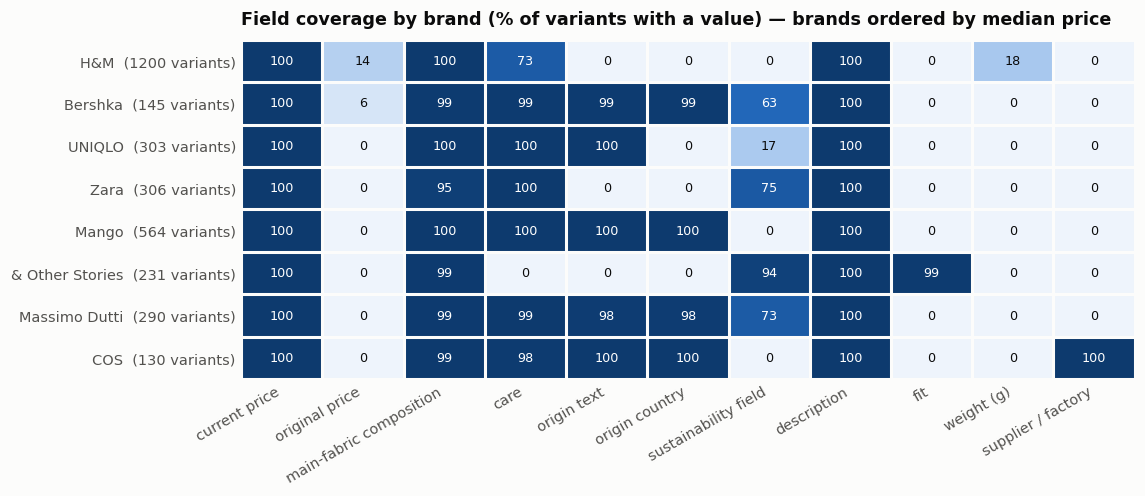

,price_current,price_original,composition_outer_raw,care_raw,origin_raw,origin_country,sustainability_raw,description_raw,fit,weight_g,supplier_factory
brand,,,,,,,,,,,
H&M,100.0,14.0,100.0,73.0,0.0,0.0,0.0,100.0,0.0,18.0,0.0
Bershka,100.0,6.0,99.0,99.0,99.0,99.0,63.0,100.0,0.0,0.0,0.0
UNIQLO,100.0,0.0,100.0,100.0,100.0,0.0,17.0,100.0,0.0,0.0,0.0
Zara,100.0,0.0,95.0,100.0,0.0,0.0,75.0,100.0,0.0,0.0,0.0
Mango,100.0,0.0,100.0,100.0,100.0,100.0,0.0,100.0,0.0,0.0,0.0
& Other Stories,100.0,0.0,99.0,0.0,0.0,0.0,94.0,100.0,99.0,0.0,0.0
Massimo Dutti,100.0,0.0,99.0,99.0,98.0,98.0,73.0,100.0,0.0,0.0,0.0
COS,100.0,0.0,99.0,98.0,100.0,100.0,0.0,100.0,0.0,0.0,100.0


In [11]:
BRAND_ORDER = models.groupby("brand")["price_median"].median().sort_values().index.tolist()  # cheapest first
COVER_FIELDS = {
    "price_current": "current price", "price_original": "original price", "composition_outer_raw": "main-fabric composition",
    "care_raw": "care", "origin_raw": "origin text", "origin_country": "origin country",
    "sustainability_raw": "sustainability field", "description_raw": "description", "fit": "fit",
    "weight_g": "weight (g)", "supplier_factory": "supplier / factory",
}
cov = variants.groupby("brand")[list(COVER_FIELDS)].agg(lambda s: s.notna().mean() * 100).loc[BRAND_ORDER]
n_var = variants["brand"].value_counts()
n_mod = models["brand"].value_counts()

fig, ax = plt.subplots(figsize=(10.5, 4.6))
heatmap(ax, cov)
ax.set_xticks(range(cov.shape[1]), [COVER_FIELDS[c] for c in cov.columns], rotation=30, ha="right")
ax.set_yticks(range(cov.shape[0]), [f"{b}  ({n_var[b]} variants)" for b in cov.index])
ax.set_title("Field coverage by brand (% of variants with a value) — brands ordered by median price", pad=10)
fig.tight_layout()
savefig(fig, "fig_coverage")
plt.show()
cov.round(0)

In [12]:
# composition parse status written by the scrapers (variant level)
pd.crosstab(variants["brand"], variants["composition_parse_status"].fillna("NaN"), margins=True).loc[BRAND_ORDER + ["All"]]

composition_parse_status,invalid_total,manual_review,missing,parsed_complete,All
brand,,,,,
H&M,0,0,0,1200,1200
Bershka,0,0,2,143,145
UNIQLO,0,0,0,303,303
Zara,3,1,14,288,306
Mango,0,0,0,564,564
& Other Stories,0,0,2,229,231
Massimo Dutti,0,0,3,287,290
COS,0,0,1,129,130
All,3,1,22,3143,3169


### 4. Outliers / Invalid Values

In [13]:
p = variants["price_current"]
print("variant price <= 0:", (p <= 0).sum(), "| missing:", p.isna().sum())
both = variants[variants["price_original"].notna() & p.notna()]
print("variants with an original price:", len(both), "| current > original:", (both["price_current"] > both["price_original"]).sum())
calc = (1 - both["price_current"] / both["price_original"]) * 100
print("max |discount_pct - computed discount|:", round((both["discount_pct"] - calc).abs().max(), 2))
no_orig = variants["on_sale"] & variants["price_original"].isna()
print("on sale but no original price:", no_orig.sum(), variants.loc[no_orig, "brand"].value_counts().to_dict())
print("models: price_min <= price_median <= price_max always:",
      ((models["price_min"] <= models["price_median"]) & (models["price_median"] <= models["price_max"])).all())

variant price <= 0: 0 | missing: 0
variants with an original price: 183 | current > original: 0
max |discount_pct - computed discount|: 0.05
on sale but no original price: 27 {'UNIQLO': 27}
models: price_min <= price_median <= price_max always: True


In [14]:
# extreme model prices: IQR rule on log price inside each brand (flag only, nothing is removed)
logp = np.log10(models["price_median"])
q1 = logp.groupby(models["brand"]).transform(lambda s: s.quantile(.25))
q3 = logp.groupby(models["brand"]).transform(lambda s: s.quantile(.75))
models["price_outlier"] = (logp < q1 - 1.5 * (q3 - q1)) | (logp > q3 + 1.5 * (q3 - q1))
print("within-brand price outliers (log-IQR):", models["price_outlier"].sum(), models.loc[models["price_outlier"], "brand"].value_counts().to_dict())
models.nlargest(8, "price_median")[["brand", "product_name", "price_median", "composition_outer_raw"]]

within-brand price outliers (log-IQR): 111 {'H&M': 38, 'Mango': 30, 'Massimo Dutti': 13, 'UNIQLO': 13, 'Bershka': 8, '& Other Stories': 5, 'Zara': 4}


,brand,product_name,price_median,composition_outer_raw
999,Massimo Dutti,100% Cashmere Ribbed Knit Cardigan,790.0,Cashmere 100%
1025,Massimo Dutti,Cashmere blend button detail cardigan,790.0,NaN
1051,Massimo Dutti,100% cashmere V-neck sweater,690.0,Cashmere 100%
1004,Massimo Dutti,100% cashmere hooded zip-up cardigan,590.0,Cashmere 100%
1008,Massimo Dutti,100% cashmere zip knit cardigan,590.0,Cashmere 100%
1056,Massimo Dutti,100% cashmere knit sweater,590.0,Cashmere 100%
1057,Massimo Dutti,100% cashmere knit sweater with button detail,590.0,Cashmere 100%
1060,Massimo Dutti,100% cashmere mock turtleneck sweater,590.0,Cashmere 100%


In [15]:
# fibre tables: do percentages add up to 100?
s_f = fibres.groupby("variant_key")["pct"].sum()
print("fibres.csv variants:", len(s_f), "| sum outside [99, 101]:", ((s_f < 99) | (s_f > 101)).sum())
mfib = [c for c in models.columns if c.endswith("_pct") and c != "max_discount_pct"]
s_m = models[mfib].sum(axis=1, min_count=1)
print("models.csv with fibre %:", s_m.notna().sum(), "| sum outside [99, 101]:", ((s_m < 99) | (s_m > 101)).sum())
print("variants parsed_complete but absent from fibres.csv:",
      (~variants.loc[variants["composition_parse_status"].eq("parsed_complete"), "variant_key"].isin(fibres["variant_key"])).sum())

fibres.csv variants: 3143 | sum outside [99, 101]: 0
models.csv with fibre %: 1537 | sum outside [99, 101]: 0
variants parsed_complete but absent from fibres.csv: 0


In [16]:
# colour variants of the same model: do price and composition differ?
var_tab = models.groupby("brand").agg(models=("model_key", "size"), multi_colour=("n_colours", lambda s: (s > 1).sum()),
                                      price_differs=("price_min", "size"), composition_differs=("composition_varies", "sum"))
var_tab["price_differs"] = (models["price_min"] != models["price_max"]).groupby(models["brand"]).sum()
var_tab.loc[BRAND_ORDER]

,models,multi_colour,price_differs,composition_differs
brand,,,,
H&M,423,288,98,36
Bershka,65,51,0,2
UNIQLO,63,63,0,2
Zara,304,2,0,0
Mango,407,127,0,48
& Other Stories,80,57,0,0
Massimo Dutti,152,66,1,0
COS,68,39,0,1


**Reading:** colours of the same model almost always share price and composition. The exceptions: at H&M 98 multi-colour models have different prices across colours, every one of them because some colours are on sale; composition differs between colours for 36 H&M and 48 Mango models, but the differences are small (e.g. 47 % vs 53 % viscose) — only 5 models see their natural share move by more than 10 points. A model-level composition (mean over colours) and a model-level price (median over colours) are therefore safe summaries.

### 5. Cleaning

#### 5.1 Composition

`fibres.csv` holds the main-fabric composition of every variant the scrapers parsed completely. Its `other` category hides several
different fibres (`fibre_names`): yak (animal), acetate (man-made cellulosic), polybutylene terephthalate (a polyester) and metallic / unspecified fibres.
These are mapped to their own group. The variants the scrapers could not parse (multiple fabric sections, trace fibres, etc.) are re-parsed with a
rule-based parser that keeps only the main / outer fabric and accepts a result only if the percentages add up to 99–101.
The parser is first validated against `fibres.csv`.

In [17]:
FIBER_MAP = [  # (regex, column) - checked in this order
    (r"yak|camel|angora|vicu", "other_animal_pct"),
    (r"cashmere", "cashmere_pct"), (r"mohair", "mohair_pct"), (r"alpaca", "alpaca_pct"),
    (r"wool|merino|lambswool", "wool_pct"), (r"silk", "silk_pct"),
    (r"cotton", "cotton_pct"), (r"linen|flax", "linen_pct"),
    (r"lyocell|tencel", "lyocell_pct"), (r"modal", "modal_pct"), (r"viscose|rayon", "viscose_pct"), (r"acetate", "acetate_pct"),
    (r"polyamide|nylon", "polyamide_pct"), (r"acrylic", "acrylic_pct"), (r"elastane|spandex", "elastane_pct"),
    (r"polyester|polybutylene terephthalate", "polyester_pct"),
    (r"metallised|metallized|metallic|other fib", "other_pct"),
]
FIBERS = list(dict.fromkeys(col for _, col in FIBER_MAP))


def fiber_col(fname):
    fname = str(fname).lower()
    for pat, col in FIBER_MAP:
        if re.search(pat, fname):
            return col
    return None


SECTION_STOP = r"\b(?:SECONDARY FABRIC|LINING|EMBELLISHMENT|DETAILS|OTHERS|TRIM|Binder-processed Part|Back:|Rib:|Woven part:)"


def main_fabric_text(raw_text):
    # keep only the main / outer fabric part of a composition string
    t = str(raw_text)
    t = re.sub(r"^COMPOSITION\s+", "", t)
    t = re.sub(r"^(?:OUTER SHELL|Outer layer:|Shell:|Composition:|Body:|Knitted part:)\s*", "", t, flags=re.I)
    t = re.sub(r"^(?:MAIN FABRIC|BODY|Face:)\s*", "", t, flags=re.I)
    t = re.split(SECTION_STOP, t)[0]
    t = re.split(r"\[Other Colors\]", t)[0]
    t = re.sub(r"\[[^\]]*\]", " ", t)
    t = re.sub(r"\(\s*\d+%\s*Uses Recycled[^)]*\)", " ", t, flags=re.I)
    t = re.sub(r"\(mulberry\)|\(recycled nylon\)", " ", t, flags=re.I)
    t = re.split(r";\s*Imported|;\s*RN:|/\s*Exclusive of Decoration|Excluding trims", t)[0]
    t = re.split(r"/", t)[0]
    t = re.sub(r"<\s*0[.,]5\s*%\s*[a-z ]+", " ", t, flags=re.I)  # trace fibres
    return t.strip()


PAIR = re.compile(r"(\d+(?:[.,]\d+)?)\s*%\s*([A-Za-z][A-Za-z \-]*)|([A-Za-z][A-Za-z \-]*?)\s+(\d+(?:[.,]\d+)?)\s*%")


def parse_composition(raw_text):
    if pd.isna(raw_text):
        return None
    out = {}
    for m in PAIR.finditer(main_fabric_text(raw_text)):
        if m.group(1):
            pct, fname = float(m.group(1).replace(",", ".")), m.group(2)
        else:
            pct, fname = float(m.group(4).replace(",", ".")), m.group(3)
        col = fiber_col(fname)
        if col is None:          # unknown fibre name -> reject the whole string
            return None
        out[col] = out.get(col, 0) + pct
    if not out or not (99 <= sum(out.values()) <= 101):
        return None
    return out


# fibres.csv -> one row per variant, 'other' split by its fibre names
OTHER_NAMES = [(r"yak|camel|angora|vicu", "other_animal_pct"), (r"acetate", "acetate_pct"),
               (r"polybutylene", "polyester_pct"), (r".", "other_pct")]


def fibre_column(fibre, names):
    if fibre != "other":
        return f"{fibre}_pct"
    return next(col for pat, col in OTHER_NAMES if re.search(pat, str(names).lower()))


fibres["column"] = [fibre_column(f, n) for f, n in zip(fibres["fibre"], fibres["fibre_names"])]
print(fibres.loc[fibres["fibre"].eq("other")].groupby(["fibre_names", "column"]).size().to_string())
scraper_fib = fibres.pivot_table(index="variant_key", columns="column", values="pct", aggfunc="sum").reindex(columns=FIBERS).fillna(0)
print("variants in fibres.csv:", len(scraper_fib))

fibre_names                     column          
acetate                         acetate_pct         2
metallic fiber                  other_pct           2
metallised fibre                other_pct           3
metallised fibre, other fibres  other_pct           1
other fibres                    other_pct           1
polybutylene terephthalate      polyester_pct       3
yak                             other_animal_pct    4
variants in fibres.csv: 3143


In [18]:
# validation: the parser on scraper-parsed variants must reproduce fibres.csv
comp_text = variants.set_index("variant_key")["composition_outer_raw"].fillna(variants.set_index("variant_key")["composition_raw"])
check = pd.DataFrame([parse_composition(comp_text[k]) or {} for k in scraper_fib.index], index=scraper_fib.index) \
    .reindex(columns=FIBERS).fillna(0)
failed = check.sum(axis=1).eq(0)
differ = ((check - scraper_fib).abs() > 0.5).any(axis=1) & ~failed
print(f"scraper-parsed variants: {len(scraper_fib)} | parser failed: {failed.sum()} | values differ: {differ.sum()}")
bad = (failed | differ)[lambda x: x].index
pd.DataFrame({"text": comp_text.reindex(bad).str[:80]}).head(10)

scraper-parsed variants: 3143 | parser failed: 0 | values differ: 0


,text
variant_key,


In [19]:
# re-parse the variants the scrapers did not parse
todo = variants.loc[~variants["variant_key"].isin(scraper_fib.index), ["variant_key", "brand", "composition_raw", "composition_outer_raw"]]
text = todo["composition_outer_raw"].fillna(todo["composition_raw"])
reparsed = text.map(parse_composition)
rec = pd.DataFrame([r for r in reparsed.dropna()], index=todo.loc[reparsed.notna(), "variant_key"]).reindex(columns=FIBERS).fillna(0)
var_fib = pd.concat([scraper_fib, rec])

summary = pd.DataFrame({
    "variants": variants["brand"].value_counts(),
    "scraper_parsed": variants["variant_key"].isin(scraper_fib.index).groupby(variants["brand"]).sum(),
    "recovered_by_reparse": variants["variant_key"].isin(rec.index).groupby(variants["brand"]).sum(),
    "no_composition_text": (variants["composition_raw"].isna() & variants["composition_outer_raw"].isna()).groupby(variants["brand"]).sum(),
}).loc[BRAND_ORDER]
summary["still_unparsed"] = summary["variants"] - summary["scraper_parsed"] - summary["recovered_by_reparse"]
summary.loc["All"] = summary.sum()
display(summary)
pd.DataFrame({"brand": todo["brand"], "main_fabric": text.map(lambda t: main_fabric_text(t)[:75] if pd.notna(t) else None),
              "recovered": reparsed.notna()}).sort_values("recovered")

,variants,scraper_parsed,recovered_by_reparse,no_composition_text,still_unparsed
brand,,,,,
H&M,1200,1200,0,0,0
Bershka,145,143,0,2,2
UNIQLO,303,303,0,0,0
Zara,306,288,18,0,0
Mango,564,564,0,0,0
& Other Stories,231,229,0,0,2
Massimo Dutti,290,287,1,2,2
COS,130,129,1,0,0
All,3169,3143,20,4,6


,brand,main_fabric,recovered
91,Bershka,None,False
99,Bershka,None,False
2180,Massimo Dutti,None,False
2263,Massimo Dutti,None,False
2630,& Other Stories,"Polyamide 85%, Spandex 15%; Shell: Rayon 100%",False
2631,& Other Stories,"Polyamide 85%, Spandex 15%; Shell: Rayon 100%",False
3250,Zara,80% viscose 20% polyamide,True
3245,Zara,73% polyester 11% polyamide 11% acrylic 5% wool,True
3183,Zara,79% wool 5% alpaca 16% polyamide,True
3159,Zara,41% acrylic 4% wool 29% polyester 26% polyamide,True


#### 5.2 Model-level composition and derived variables

In [20]:
# model composition = mean over its colour variants with a usable composition
vf = var_fib.join(variants.set_index("variant_key")["model_key"])
mod_fib = vf.groupby("model_key")[FIBERS].mean()
n_comp = vf.groupby("model_key").size()

# check against models.csv for models whose variants were all parsed by the scrapers
comparable = models.set_index("model_key")
only_scraper = vf.assign(s=vf.index.isin(scraper_fib.index)).groupby("model_key")["s"].all()
keys = only_scraper[only_scraper].index.intersection(comparable.index[comparable["cotton_pct"].notna()])
cols14 = [c for c in mfib if c != "other_pct"]
diff = (mod_fib.loc[keys, cols14] - comparable.loc[keys, cols14]).abs().max(axis=1)
print(f"models compared with models.csv: {len(keys)} | max abs difference > 0.5 pp: {(diff > 0.5).sum()}")

models = models.drop(columns=[c for c in FIBERS if c in models.columns])
models = models.join(mod_fib, on="model_key")
models["n_variants_with_composition"] = models["model_key"].map(n_comp).fillna(0).astype(int)
models["has_composition"] = models["n_variants_with_composition"] > 0

FIBER_GROUPS = {
    "Animal natural": ["wool_pct", "cashmere_pct", "mohair_pct", "alpaca_pct", "silk_pct", "other_animal_pct"],
    "Plant natural": ["cotton_pct", "linen_pct"],
    "Man-made cellulosic": ["viscose_pct", "lyocell_pct", "modal_pct", "acetate_pct"],
    "Synthetic": ["polyester_pct", "acrylic_pct", "polyamide_pct", "elastane_pct"],
    "Other": ["other_pct"],
}
GROUP_COL = {"Animal natural": "animal_pct", "Plant natural": "plant_pct", "Man-made cellulosic": "cellulosic_pct",
             "Synthetic": "synthetic_pct", "Other": "other_group_pct"}
for g, cols in FIBER_GROUPS.items():
    models[GROUP_COL[g]] = models[cols].sum(axis=1, min_count=1)
models["natural_pct"] = models["animal_pct"] + models["plant_pct"]
models["wool_cashmere_pct"] = models["wool_pct"] + models["cashmere_pct"]

has = models["has_composition"]
models["all_natural"] = (models["natural_pct"] >= 99.5).where(has)
models["any_synthetic"] = (models["synthetic_pct"] > 0).where(has)
models["synthetic_majority"] = (models["synthetic_pct"] > 50).where(has)
models["contains_wool_or_cashmere"] = (models["wool_cashmere_pct"] > 0).where(has)
FLAG_COLS = ["all_natural", "any_synthetic", "synthetic_majority", "contains_wool_or_cashmere"]
models[FLAG_COLS] = models[FLAG_COLS].astype("boolean")
models["dominant_fiber"] = models.loc[has, FIBERS].idxmax(axis=1).str.replace("_pct", "").reindex(models.index)
models["n_fibers"] = (models[FIBERS] > 0.5).sum(axis=1).where(has)
print(models.loc[has, ["natural_pct", "synthetic_pct", "cellulosic_pct", "other_group_pct"]].sum(axis=1).describe().round(2).to_string())

models compared with models.csv: 1537 | max abs difference > 0.5 pp: 1
count    1557.0
mean      100.0
std         0.0
min       100.0
25%       100.0
50%       100.0
75%       100.0
max       100.0


**Reading:** the scrapers now parse 3,143 of 3,169 variants (99.2 %). The rule-based parser reproduces all of them exactly (0 differences) and recovers 20 more (18 Zara items whose label also lists a lining or secondary fabric, 1 Massimo Dutti, 1 COS). Six variants stay without a composition: 4 have no composition text and 2 & Other Stories items list two different shells. At model level the result matches `models.csv` for 1,536 of 1,537 comparable models; the one difference is an H&M model whose 15 % polybutylene terephthalate is counted here as polyester (which it is) instead of "other".

In [21]:
# price: model price = median current price over its colours; 'regular' price undoes the sale where the original is known
models["price"] = models["price_median"]
models["log10_price"] = np.log10(models["price"])
variants["price_regular"] = variants["price_original"].where(variants["on_sale"] & variants["price_original"].notna(),
                                                             variants["price_current"])
models["price_regular"] = models["model_key"].map(variants.groupby("model_key")["price_regular"].median())
models["share_colours_on_sale"] = models["model_key"].map(variants.groupby("model_key")["on_sale"].mean())
models[["price", "price_regular", "share_colours_on_sale"]].describe().round(2)

,price,price_regular,share_colours_on_sale
count,1562.00,1562.00,1562.00
mean,90.90,91.10,0.04
std,82.15,82.02,0.15
min,9.90,9.90,0.00
25%,49.90,49.90,0.00
50%,69.99,69.99,0.00
75%,99.90,99.90,0.00
max,790.00,790.00,1.00


In [22]:
# care (variant level): the most demanding washing method on the label
def care_category(t):
    if pd.isna(t):
        return np.nan
    s = t.lower()
    if re.search(r"machine wash|gentle cycle|delicate cycle", s):
        return "Machine wash"
    if re.search(r"hand wash", s):
        return "Hand wash"
    if re.search(r"dry clean", s) and not re.search(r"do not dry clean", s):
        return "Dry clean only"
    if re.search(r"do not wash|not washable|unwashable|specialist cleaning", s):
        return "Do not wash"
    return "No washing instruction"


variants["care_category"] = variants["care_raw"].map(care_category)
care_mode = variants.dropna(subset=["care_category"]).groupby("model_key")["care_category"].agg(lambda s: s.value_counts().index[0])
models["care_category"] = models["model_key"].map(care_mode)
pd.crosstab(variants["brand"], variants["care_category"].fillna("no care text")).loc[BRAND_ORDER]

care_category,Do not wash,Dry clean only,Hand wash,Machine wash,No washing instruction,no care text
brand,,,,,,
H&M,0,100,29,743,0,328
Bershka,0,4,23,22,94,2
UNIQLO,0,11,159,133,0,0
Zara,0,2,66,238,0,0
Mango,0,0,525,38,1,0
& Other Stories,0,0,0,0,0,231
Massimo Dutti,1,0,287,0,0,2
COS,0,32,0,96,0,2


In [23]:
# origin: models.csv gives the country; variants tell how origin is reported and Mango's production stages
origin_raw = variants.groupby("model_key")["origin_raw"].agg(lambda s: "; ".join(s.dropna().unique()) or np.nan)
models["origin_raw"] = models["model_key"].map(origin_raw)
made_in = models["origin_raw"].str.extract(r"(?i)made in\s+([a-z]+)")[0].str.title()
models["origin_country_std"] = models["origin_country"].fillna(made_in).replace({"Türkiye": "Turkey", "Mainland China": "China"})
models["origin_status"] = np.select(
    [models["origin_country_std"].notna(), models["origin_raw"].str.contains("imported", case=False, na=False)],
    ["country given", "'Imported' only"], default="not available")
stages = models["origin_raw"].str.extract(
    r"Manufacture:\s*(?P<manufacture>[^;]+)(?:;\s*Dye/printing:\s*(?P<dye>[^;]+))?(?:;\s*Weave:\s*(?P<weave>[^;]+))?")
for c in stages:
    models[f"origin_{c}"] = stages[c].str.strip().replace({"Türkiye": "Turkey"})
pd.crosstab(models["brand"], models["origin_status"]).loc[BRAND_ORDER]

origin_status,'Imported' only,country given,not available
brand,,,
H&M,0,0,423
Bershka,0,63,2
UNIQLO,62,1,0
Zara,0,0,304
Mango,0,407,0
& Other Stories,0,0,80
Massimo Dutti,0,146,6
COS,0,68,0


In [24]:
# sustainability claims (variant level, then 'any colour' per model). Where a claim can be found differs by brand:
CLAIM_SOURCE = {"Zara": "sustainability field", "Massimo Dutti": "sustainability field", "Bershka": "sustainability field",
                "& Other Stories": "sustainability field", "UNIQLO": "sustainability field",
                "Mango": "composition text", "COS": "description", "H&M": "none captured"}
CERT_RE = r"(?i)\b(?:RWS|RCS|OCS|RMS|RAS|GCS|GOTS|GRS|responsible (?:wool|mohair) standard|certified)\b"
REC_BEFORE = re.compile(r"(?i)(\d+(?:\.\d+)?)\s*%\s*(?:uses\s+)?(?:RCS[- ]certified\s+)?recycled\s+([a-z]+)")  # "29% RCS-certified recycled polyamide"
REC_AFTER = re.compile(r"(?i)(?:^|[:,]\s*)recycled\s+([a-z]+)\s+(\d+(?:\.\d+)?)\s*%")                   # "Shell: Recycled polyamide 38%"
TEXT_SOURCES = ["sustainability_raw", "composition_raw", "description_raw"]


def recycled_share(text):
    # recycled % of the main fabric: first statement per fibre (later ones describe other parts), summed over fibres
    if pd.isna(text):
        return 0.0
    main = re.split(SECTION_STOP, text)[0]
    found = [(m.start(), m.group(2).lower(), float(m.group(1))) for m in REC_BEFORE.finditer(main)]
    found += [(m.start(), m.group(1).lower(), float(m.group(2))) for m in REC_AFTER.finditer(main)]
    first = {}
    for _, fibre, pct in sorted(found):
        first.setdefault(fibre, pct)
    return sum(first.values())


rec_by_source = pd.concat({c: variants[c].map(recycled_share) for c in TEXT_SOURCES}, axis=1)
text_all = variants[TEXT_SOURCES].fillna("").agg(" ".join, axis=1)
variants["claim_source"] = variants["brand"].map(CLAIM_SOURCE)
details_seen = variants[["composition_raw", "care_raw", "origin_raw", "sustainability_raw"]].notna().any(axis=1)
variants["claim_observable"] = details_seen & variants["claim_source"].ne("none captured")
variants["recycled_pct"] = rec_by_source.max(axis=1).clip(upper=100).where(variants["claim_observable"])
variants["recycled_claim"] = (variants["recycled_pct"].gt(0) | text_all.str.contains("recycl", case=False)).where(variants["claim_observable"])
variants["certified_claim"] = text_all.str.contains(CERT_RE).where(variants["claim_observable"])
variants["organic_claim"] = text_all.str.contains("organic", case=False).where(variants["claim_observable"])
CLAIM_COLS = ["recycled_claim", "certified_claim", "organic_claim"]
variants[CLAIM_COLS] = variants[CLAIM_COLS].astype("boolean")
variants["any_claim"] = variants["recycled_claim"] | variants["certified_claim"] | variants["organic_claim"]

obs_v = variants[variants["claim_observable"]]
claims = obs_v.groupby("model_key").agg(recycled_claim=("recycled_claim", "any"), certified_claim=("certified_claim", "any"),
                                        organic_claim=("organic_claim", "any"), any_claim=("any_claim", "any"),
                                        recycled_pct=("recycled_pct", "mean"))
models = models.drop(columns=[c for c in claims.columns if c in models.columns]).join(claims, on="model_key")
models[["recycled_claim", "certified_claim", "organic_claim", "any_claim"]] = \
    models[["recycled_claim", "certified_claim", "organic_claim", "any_claim"]].astype("boolean")
models["claim_source"] = models["brand"].map(CLAIM_SOURCE)
models["claim_observable"] = models["model_key"].isin(obs_v["model_key"])
models.groupby("brand")[["claim_observable", "recycled_claim", "certified_claim", "organic_claim"]].sum().loc[BRAND_ORDER]

,claim_observable,recycled_claim,certified_claim,organic_claim
brand,,,,
H&M,0,0,0,0
Bershka,63,42,44,0
UNIQLO,63,10,0,0
Zara,304,203,226,4
Mango,407,9,0,0
& Other Stories,80,12,67,0
Massimo Dutti,150,70,121,34
COS,68,5,8,0


In [25]:
KEEP = ["model_key", "brand", "segment", "model_id", "product_name", "category", "subcategory", "is_cape", "n_colours",
        "first_collected", "last_collected",
        "price", "price_min", "price_max", "price_regular", "log10_price", "price_outlier", "any_on_sale", "max_discount_pct",
        "share_colours_on_sale",
        "has_composition", "n_variants_with_composition", "composition_varies", "composition_outer_raw", *FIBERS,
        "animal_pct", "plant_pct", "natural_pct", "cellulosic_pct", "synthetic_pct", "other_group_pct", "wool_cashmere_pct",
        "all_natural", "any_synthetic", "synthetic_majority", "contains_wool_or_cashmere", "dominant_fiber", "n_fibers",
        "origin_status", "origin_country_std", "origin_manufacture", "origin_dye", "origin_weave",
        "claim_source", "claim_observable", "recycled_pct", "recycled_claim", "certified_claim", "organic_claim", "any_claim",
        "care_category"]
clean = models[KEEP].copy()
clean.to_csv("models_clean.csv", index=False)
print("saved models_clean.csv:", clean.shape)

saved models_clean.csv: (1562, 67)


#### 5.3 Numeric Describe (Clean Dataset, model level)

In [26]:
NUM = ["price", "price_regular", "max_discount_pct", "n_colours", "natural_pct", "animal_pct", "wool_cashmere_pct",
       "plant_pct", "cellulosic_pct", "synthetic_pct", "recycled_pct", "n_fibers"]
d = clean[NUM].describe().T
d["median"] = clean[NUM].median()
d["skew"] = clean[NUM].skew()
d["kurtosis"] = clean[NUM].kurt()
d["n_missing"] = clean[NUM].isna().sum()
d.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skew,kurtosis,n_missing
price,1562.0,90.90,82.15,9.9,49.90,69.99,99.9,790.0,69.99,3.56,17.72,0
price_regular,1562.0,91.10,82.02,9.9,49.90,69.99,99.9,790.0,69.99,3.58,17.81,0
max_discount_pct,114.0,43.74,15.75,23.3,26.28,43.30,60.0,70.9,43.30,-0.05,-1.78,1448
n_colours,1562.0,2.03,2.23,1.0,1.00,1.00,2.0,37.0,1.00,7.46,90.63,0
natural_pct,1557.0,37.93,42.12,0.0,0.00,8.00,98.0,100.0,8.00,0.56,-1.47,5
animal_pct,1557.0,27.00,39.72,0.0,0.00,5.00,55.0,100.0,5.00,1.12,-0.57,5
wool_cashmere_pct,1557.0,25.35,38.88,0.0,0.00,5.00,32.0,100.0,5.00,1.25,-0.24,5
plant_pct,1557.0,10.93,25.85,0.0,0.00,0.00,0.0,100.0,0.00,2.35,4.41,5
cellulosic_pct,1557.0,11.81,24.13,0.0,0.00,0.00,0.0,100.0,0.00,1.92,2.40,5
synthetic_pct,1557.0,50.23,40.42,0.0,0.00,50.00,94.0,100.0,50.00,-0.05,-1.67,5


### 6. Normality (Shapiro-Wilk, D'Agostino K2)

In [27]:
rows = []
for col in ["price", "log10_price", "natural_pct", "wool_cashmere_pct", "synthetic_pct"]:
    x = clean[col].dropna()
    rows.append({"variable": col, "n": len(x), "skew": x.skew(),
                 "shapiro_W": stats.shapiro(x).statistic, "shapiro_p": stats.shapiro(x).pvalue,
                 "K2": stats.normaltest(x).statistic, "K2_p": stats.normaltest(x).pvalue})
display(tidy(pd.DataFrame(rows).set_index("variable")))
rows = []
for b in BRAND_ORDER:
    x = clean.loc[clean["brand"] == b, "log10_price"].dropna()
    rows.append({"brand": b, "n": len(x), "skew": x.skew(), "shapiro_p": stats.shapiro(x).pvalue, "n_distinct_prices": x.nunique()})
tidy(pd.DataFrame(rows).set_index("brand"))

,n,skew,shapiro_W,shapiro_p,K2,K2_p
variable,,,,,,
price,1562,3.561,0.649,8.3e-49,1214.406,2.0e-264
log10_price,1562,0.559,0.973,1.3e-16,94.821,2.6e-21
natural_pct,1557,0.558,0.750,1.8e-43,11779.829,0.0e+00
wool_cashmere_pct,1557,1.249,0.635,2.4e-49,261.833,1.4e-57
synthetic_pct,1557,-0.050,0.828,6.2e-38,7510.837,0.0e+00


,n,skew,shapiro_p,n_distinct_prices
brand,,,,
H&M,423,0.844,2.8e-12,36
Bershka,65,1.029,2.3e-04,14
UNIQLO,63,-0.416,6.1e-05,11
Zara,304,1.331,3.9e-14,15
Mango,407,2.129,4.4e-22,17
& Other Stories,80,0.435,0.001,12
Massimo Dutti,152,0.803,1.5e-07,16
COS,68,0.310,8.7e-04,18


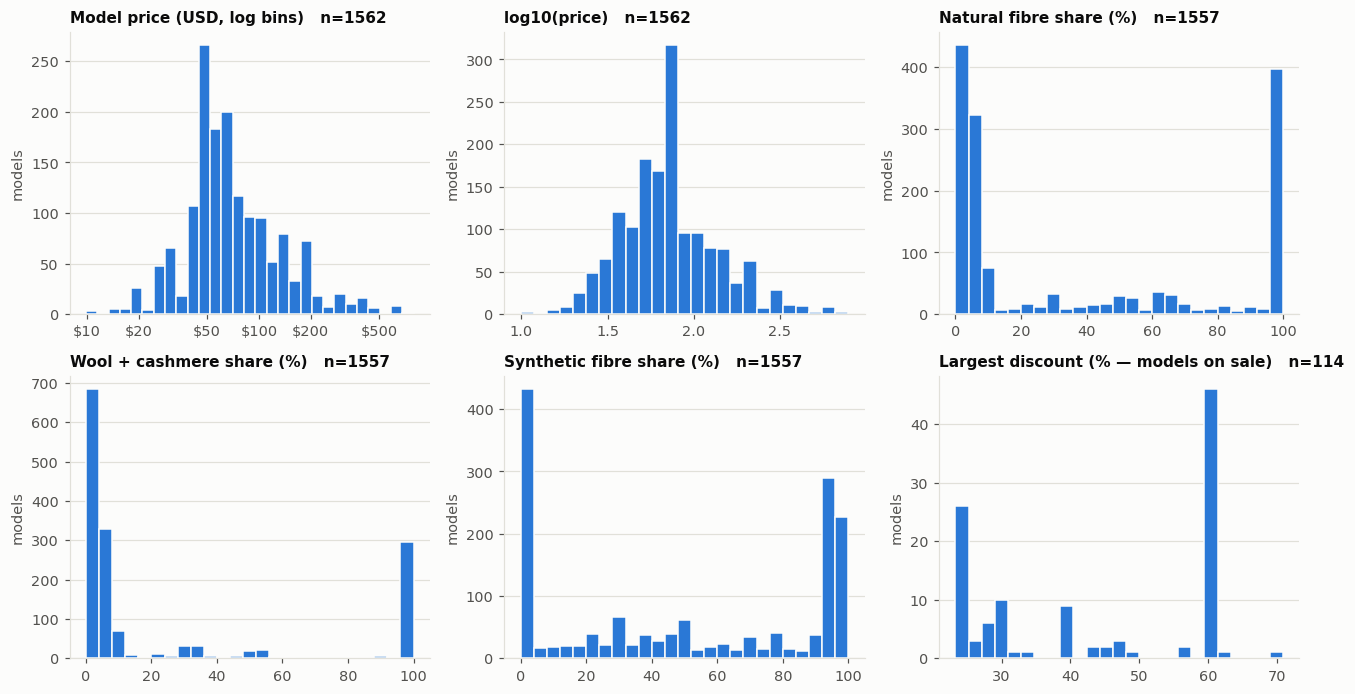

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
panels = [("price", "Model price (USD, log bins)"), ("log10_price", "log10(price)"),
          ("natural_pct", "Natural fibre share (%)"), ("wool_cashmere_pct", "Wool + cashmere share (%)"),
          ("synthetic_pct", "Synthetic fibre share (%)"), ("max_discount_pct", "Largest discount (% — models on sale)")]
for ax, (col, title) in zip(axes.flat, panels):
    x = clean[col].dropna()
    if col == "max_discount_pct":
        x = x[x > 0]
    if col == "price":
        ax.hist(x, bins=np.logspace(np.log10(x.min()), np.log10(x.max()), 30), color=BLUE, edgecolor=SURFACE, linewidth=1)
        ax.set_xscale("log")
        usd_axis(ax, ticks=(10, 20, 50, 100, 200, 500))
    else:
        ax.hist(x, bins=25, color=BLUE, edgecolor=SURFACE, linewidth=1)
    ax.set_title(f"{title}   n={len(x)}", fontsize=10)
    ax.set_ylabel("models")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
savefig(fig, "fig_distributions")
plt.show()

**Reading:** no variable is normal (all p < 1e-15), log price included (W = 0.97). Two features matter later:
- prices sit on a few round price points per brand (11–36 distinct values per brand);
- fibre shares are **bimodal**: most models are either almost fully synthetic / blended (< 10 % natural) or 100 % natural, with little in between.

→ Medians and IQRs, rank-based tests (Kruskal-Wallis, Mann-Whitney, Spearman), and log price in any regression.

---
# Part 2 — Descriptive results

### 7. Price

Model price = median current price over the model's colours (`price_median`). Sale items are kept; 7.3 repeats the brand comparison with the
regular (pre-sale) price where it is known. Prices are right-skewed, so medians, IQRs and rank-based tests are reported and charts use a log scale.

In [29]:
prices = clean.dropna(subset=["price"])
tab = prices.groupby("brand")["price"].agg(
    n="count", median="median", q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75),
    mean="mean", min="min", max="max").loc[BRAND_ORDER]
tab.insert(0, "segment", tab.index.map(SEGMENT))
tab.round(2)

,segment,n,median,q1,q3,mean,min,max
brand,,,,,,,,
H&M,Fast fashion,423,39.99,29.99,49.99,50.50,14.99,239.00
Bershka,Fast fashion,65,49.90,39.90,49.90,51.48,29.90,119.00
UNIQLO,Mid/premium,63,49.90,34.90,49.90,48.87,9.90,159.90
Zara,Fast fashion,304,59.90,49.90,79.90,69.38,39.90,319.00
Mango,Fast fashion,407,69.99,69.99,89.99,81.76,45.99,499.99
& Other Stories,Mid/premium,80,129.00,119.00,169.00,143.12,69.00,379.00
Massimo Dutti,Mid/premium,152,180.00,130.00,220.00,220.00,90.00,790.00
COS,Mid/premium,68,199.00,139.00,281.75,219.60,79.00,449.00


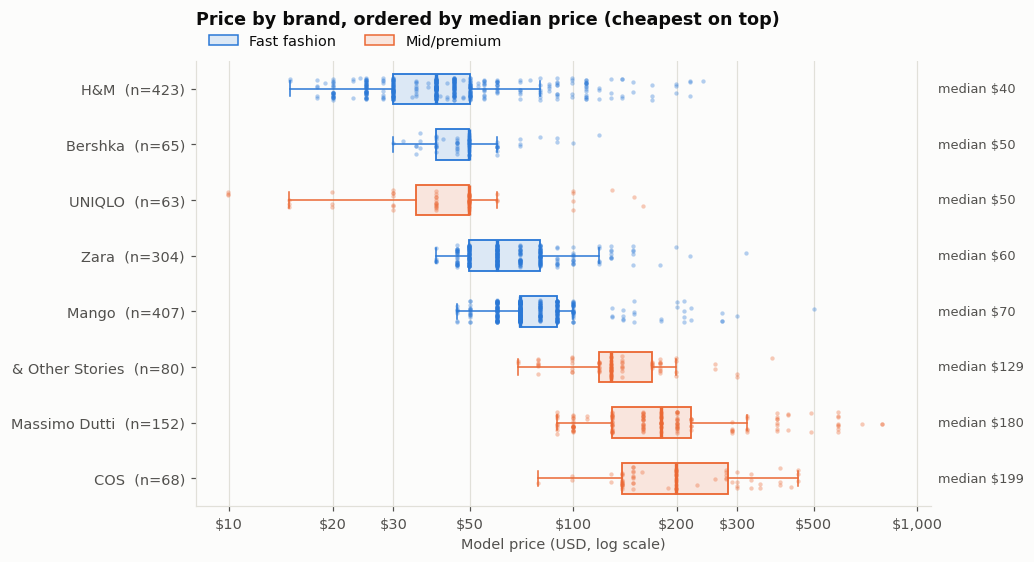

In [30]:
rng = np.random.default_rng(7)
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ypos = np.arange(len(BRAND_ORDER))[::-1]   # cheapest on top
for yi, b in zip(ypos, BRAND_ORDER):
    vals = prices.loc[prices["brand"] == b, "price"].to_numpy()
    col = SEG_COLORS[SEGMENT[b]]
    ax.boxplot(vals, positions=[yi], vert=False, widths=0.55, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor=col + "26", edgecolor=col, linewidth=1.2),
               medianprops=dict(color=col, linewidth=2.2), whiskerprops=dict(color=col, linewidth=1),
               capprops=dict(color=col, linewidth=1))
    ax.scatter(vals, yi + rng.uniform(-0.2, 0.2, len(vals)), s=8, color=col, alpha=0.35, linewidths=0, zorder=3)
    ax.text(1150, yi, f"median ${np.median(vals):,.0f}", va="center", ha="left", fontsize=8.5, color=INK2)
ax.set_xscale("log")
ax.set_xlim(8, 1100)
usd_axis(ax)
ax.set_yticks(ypos, [f"{b}  (n={(prices['brand'] == b).sum()})" for b in BRAND_ORDER])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Model price (USD, log scale)")
ax.legend(handles=[Patch(facecolor=c + "26", edgecolor=c, label=s) for s, c in SEG_COLORS.items()],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
ax.set_title("Price by brand, ordered by median price (cheapest on top)", pad=24)
fig.tight_layout()
savefig(fig, "fig_price_by_brand")
plt.show()

In [31]:
# Kruskal-Wallis across brands, epsilon^2 = H / (n - 1)
H, p = stats.kruskal(*[g["price"].to_numpy() for _, g in prices.groupby("brand")])
print(f"Kruskal-Wallis ({prices['brand'].nunique()} brands): H = {H:.1f}, p = {p:.2e}, epsilon^2 = {H / (len(prices) - 1):.3f}")
mid, fast = prices["segment"] == "Mid/premium", prices["segment"] == "Fast fashion"
seg = pd.DataFrame({
    "all brands": mann_whitney(prices.loc[mid, "price"], prices.loc[fast, "price"]),
    "without UNIQLO": mann_whitney(prices.loc[mid & (prices["brand"] != "UNIQLO"), "price"], prices.loc[fast, "price"]),
}).T.rename(columns={"n_a": "n_mid_premium", "n_b": "n_fast", "median_a": "median_mid_premium", "median_b": "median_fast"})
tidy(seg)

Kruskal-Wallis (8 brands): H = 935.6, p = 9.64e-198, epsilon^2 = 0.599


,n_mid_premium,n_fast,median_mid_premium,median_fast,U,p,r_rb
all brands,363,1199,139.0,59.99,366923.5,1.1e-87,0.686
without UNIQLO,300,1199,160.0,59.99,345208.0,1.4e-134,0.919


**Reading:** brand explains a large part of the price variation (Kruskal-Wallis ε² = 0.60). The four fast-fashion brands have medians between $40 and $70; & Other Stories ($129), Massimo Dutti ($180) and COS ($199) form a clearly separate tier. **UNIQLO (median $50) is priced like fast fashion**, between Bershka and Zara, not like the mid/premium segment it was assigned to. Mid/premium vs fast fashion: r_rb = 0.69 with UNIQLO, 0.92 without.

→ For the research questions, give UNIQLO its own "affordable basics" group or work with price and brand directly instead of the segment label.

#### 7.2 Sweaters vs cardigans

In [32]:
rows = []
for b in BRAND_ORDER:
    g = prices[prices["brand"] == b]
    r = mann_whitney(g.loc[g["category"] == "cardigan", "price"], g.loc[g["category"] == "sweater", "price"])
    rows.append({"brand": b, "n_cardigan": r["n_a"], "n_sweater": r["n_b"], "median_cardigan": r["median_a"],
                 "median_sweater": r["median_b"], "p": r["p"], "r_rb": r["r_rb"]})
cat_tab = pd.DataFrame(rows).set_index("brand")
cat_tab["p_BH"] = bh(cat_tab["p"])
tidy(cat_tab)

,n_cardigan,n_sweater,median_cardigan,median_sweater,p,r_rb,p_BH
brand,,,,,,,
H&M,195,228,39.99,44.99,0.007,-0.151,0.019
Bershka,14,51,49.90,49.90,0.733,0.060,0.733
UNIQLO,15,48,29.90,49.90,0.036,-0.350,0.058
Zara,122,182,64.90,59.90,0.234,0.079,0.312
Mango,101,306,79.99,69.99,0.002,0.196,0.018
& Other Stories,41,39,129.00,129.00,0.697,-0.051,0.733
Massimo Dutti,52,100,200.00,160.00,0.006,0.271,0.019
COS,31,37,149.00,199.00,0.022,-0.321,0.045


**Reading:** cardigans and sweaters differ in price in 4 brands after BH correction, but in **opposite directions** (cardigans pricier at Mango and Massimo Dutti, cheaper at H&M and COS; UNIQLO borderline). Category is not a consistent price driver; keep it as a control variable.

#### 7.3 Sales and discounts

In [33]:
sale = variants.groupby("brand").agg(
    variants=("brand", "size"), on_sale=("on_sale", "sum"), with_original_price=("price_original", "count"),
    median_discount=("discount_pct", "median"), min_discount=("discount_pct", "min"), max_discount=("discount_pct", "max"),
).loc[BRAND_ORDER]
sale["on_sale_pct"] = (sale["on_sale"] / sale["variants"] * 100).round(1)
sale["models_with_a_colour_on_sale"] = clean.groupby("brand")["any_on_sale"].sum()
sale

,variants,on_sale,with_original_price,median_discount,min_discount,max_discount,on_sale_pct,models_with_a_colour_on_sale
brand,,,,,,,,
H&M,1200,174,174,40.0,22.2,70.9,14.5,109
Bershka,145,9,9,30.0,30.0,30.0,6.2,5
UNIQLO,303,27,0,NaN,NaN,NaN,8.9,27
Zara,306,0,0,NaN,NaN,NaN,0.0,0
Mango,564,0,0,NaN,NaN,NaN,0.0,0
& Other Stories,231,0,0,NaN,NaN,NaN,0.0,0
Massimo Dutti,290,0,0,NaN,NaN,NaN,0.0,0
COS,130,0,0,NaN,NaN,NaN,0.0,0


In [34]:
# robustness: brand comparison on the regular price (sale undone where the original price is known)
H2, p2 = stats.kruskal(*[g["price_regular"].dropna().to_numpy() for _, g in clean.groupby("brand")])
print(f"regular price: H = {H2:.1f}, p = {p2:.2e}, epsilon^2 = {H2 / (clean['price_regular'].notna().sum() - 1):.3f}")
pd.DataFrame({"median_price": prices.groupby("brand")["price"].median(),
              "median_regular_price": clean.groupby("brand")["price_regular"].median()}).loc[BRAND_ORDER]

regular price: H = 932.6, p = 4.34e-197, epsilon^2 = 0.597


,median_price,median_regular_price
brand,,
H&M,39.99,39.99
Bershka,49.90,49.90
UNIQLO,49.90,49.90
Zara,59.90,59.90
Mango,69.99,69.99
& Other Stories,129.00,129.00
Massimo Dutti,180.00,180.00
COS,199.00,199.00


**Reading:** sales are concentrated at H&M: 174 of its 1,200 colour variants (14.5 %) were on sale, 22–71 % off (median 40 %), touching 109 models. Bershka had 9 variants at 30 % off; UNIQLO flags 27 variants as on sale but shows no original price, so their discount cannot be measured. Zara, Mango, Massimo Dutti, & Other Stories and COS had no sale items. Using the regular price instead of the current price changes no brand median and leaves ε² at 0.60, so the model price (median current price over colours) is safe to use.

#### 7.4 H&M "Premium Selection" vs the rest of H&M

H&M sells a premium line inside the same store, which gives a within-brand view of price vs fibre that is not confounded by brand.

In [35]:
hm = clean[clean["brand"] == "H&M"].copy()
hm["line"] = np.where(hm["subcategory"].eq("premium selection"), "Premium Selection", "Regular")
hm_tab = hm.groupby("line").agg(n=("line", "size"), median_price=("price", "median"),
                                with_composition=("has_composition", "sum"), median_natural_pct=("natural_pct", "median"),
                                mean_natural_pct=("natural_pct", "mean"), mean_wool_cashmere_pct=("wool_cashmere_pct", "mean"),
                                pct_all_natural=("all_natural", "mean"), pct_synthetic_majority=("synthetic_majority", "mean"))
hm_tab[["pct_all_natural", "pct_synthetic_majority"]] *= 100
display(hm_tab.round(1))
pd.DataFrame({v: mann_whitney(hm.loc[hm["line"] == "Premium Selection", v], hm.loc[hm["line"] == "Regular", v])
              for v in ["price", "natural_pct", "wool_cashmere_pct", "synthetic_pct"]}).T \
  .rename(columns={"n_a": "n_premium", "n_b": "n_regular", "median_a": "median_premium", "median_b": "median_regular"}).pipe(tidy)

,n,median_price,with_composition,median_natural_pct,mean_natural_pct,mean_wool_cashmere_pct,pct_all_natural,pct_synthetic_majority
line,,,,,,,,
Premium Selection,75,109.0,75,100.0,90.3,80.2,64.0,0.0
Regular,348,40.0,348,5.0,10.1,3.2,1.1,76.7


,n_premium,n_regular,median_premium,median_regular,U,p,r_rb
price,75,348,109.0,39.99,25720.5,3.4e-40,0.971
natural_pct,75,348,100.0,5.00,25777.0,6.3e-42,0.975
wool_cashmere_pct,75,348,100.0,3.00,26045.5,1.6e-45,0.996
synthetic_pct,75,348,0.0,95.00,943.5,3.6e-37,-0.928


**Reading:** inside H&M the Premium Selection line (75 models, median $109 vs $40) is almost a different product: median 100 % natural (64 % fully natural), mean wool + cashmere 80 % vs 3 %, and no synthetic-majority model (vs 77 % in the regular line). It is the clearest within-brand evidence that higher price goes with natural fibres — and the reason to analyse this line separately, because it carries all of H&M's price × fibre correlation (Section 9).

#### 7.5 Price differences between colours of the same model

In [36]:
multi = clean[clean["n_colours"] > 1].copy()
multi["spread_pct"] = (multi["price_max"] / multi["price_min"] - 1) * 100
pd.DataFrame({
    "multi_colour_models": multi.groupby("brand").size(),
    "price_differs": multi.groupby("brand")["spread_pct"].agg(lambda s: (s > 0).sum()),
    "of_which_a_colour_on_sale": multi[multi["spread_pct"] > 0].groupby("brand")["any_on_sale"].sum(),
    "median_spread_if_differs_pct": multi[multi["spread_pct"] > 0].groupby("brand")["spread_pct"].median(),
}).reindex(BRAND_ORDER).fillna(0).round(1)

,multi_colour_models,price_differs,of_which_a_colour_on_sale,median_spread_if_differs_pct
brand,,,,
H&M,288,98,98.0,128.3
Bershka,51,0,0.0,0.0
UNIQLO,63,0,0.0,0.0
Zara,2,0,0.0,0.0
Mango,127,0,0.0,0.0
& Other Stories,57,0,0.0,0.0
Massimo Dutti,66,1,0.0,23.1
COS,39,0,0.0,0.0


**Reading:** only H&M prices colours of the same model differently (98 models, all because of sales); in the median case the cheapest colour costs less than half of the most expensive one. Every other brand charges one price per model. This is why the model price is the median over colours and why the regular price is used as a check in 7.3.

### 8. Fibre composition

Groups: **animal natural** (wool, cashmere, mohair, alpaca, silk, yak), **plant natural** (cotton, linen),
**man-made cellulosic** (viscose/rayon, lyocell, modal, acetate — wood-pulp based but chemically processed, so not counted as natural),
**synthetic** (polyester, acrylic, polyamide, elastane) and **other** (metallic or unspecified fibre). Only the main / outer fabric is used;
a model's composition is the mean over its colours.

In [37]:
comp = clean[clean["has_composition"]]
COMP_BRANDS = [b for b in BRAND_ORDER if b in comp["brand"].unique()]
grp = comp.groupby("brand")[list(GROUP_COL.values())].mean().loc[COMP_BRANDS]
grp.columns = list(GROUP_COL)
grp.insert(0, "n_with_composition", comp["brand"].value_counts())
grp.insert(1, "coverage_pct", (comp["brand"].value_counts() / clean["brand"].value_counts() * 100).round(1))
grp.round(1)

,n_with_composition,coverage_pct,Animal natural,Plant natural,Man-made cellulosic,Synthetic,Other
brand,,,,,,,
H&M,423,100.0,18.3,6.0,9.4,66.2,0.0
Bershka,63,96.9,8.6,5.1,13.1,73.2,0.0
UNIQLO,63,100.0,35.3,22.5,8.9,33.3,0.0
Zara,304,100.0,23.5,6.2,12.7,57.5,0.2
Mango,407,100.0,9.5,13.3,18.4,58.8,0.0
& Other Stories,79,98.8,64.4,21.3,3.9,10.4,0.0
Massimo Dutti,150,98.7,67.1,21.1,6.5,5.4,0.0
COS,68,100.0,78.9,8.7,5.7,6.8,0.0


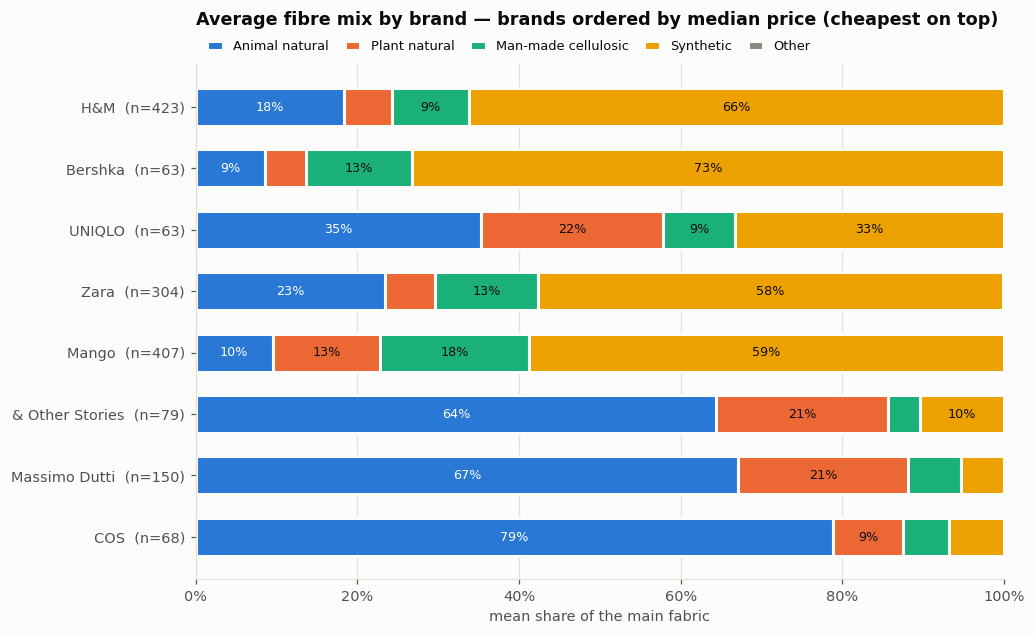

In [38]:
share = grp[list(GROUP_COL)].reindex(BRAND_ORDER)
labels = [f"{b}  (n={int(grp.loc[b, 'n_with_composition'])})" if b in grp.index else f"{b}  (n=0)" for b in BRAND_ORDER]
notes = {b: "no composition data" for b in BRAND_ORDER if b not in grp.index}
fig, ax = stacked_bars(share, {"Animal natural": BLUE, "Plant natural": ORANGE, "Man-made cellulosic": AQUA,
                               "Synthetic": YELLOW, "Other": NEUTRAL},
                       labels, notes=notes, xlabel="mean share of the main fabric",
                       title="Average fibre mix by brand — brands ordered by median price (cheapest on top)",
                       fname="fig_fiber_groups")
plt.show()

In [39]:
flags = comp.groupby("brand").agg(
    n=("brand", "size"),
    median_natural_pct=("natural_pct", "median"),
    pct_all_natural=("all_natural", "mean"),
    pct_contains_wool_or_cashmere=("contains_wool_or_cashmere", "mean"),
    mean_wool_cashmere_pct=("wool_cashmere_pct", "mean"),
    median_wool_cashmere_if_present=("wool_cashmere_pct", lambda s: s[s > 0].median()),
    pct_any_synthetic=("any_synthetic", "mean"),
    pct_synthetic_majority=("synthetic_majority", "mean"),
    pct_below_10_natural=("natural_pct", lambda s: (s < 10).mean()),
    pct_contains_cashmere=("cashmere_pct", lambda s: (s > 0).mean()),
    mean_n_fibers=("n_fibers", "mean"),
).loc[COMP_BRANDS]
for c in [c for c in flags if c.startswith("pct_")]:
    flags[c] *= 100
flags.round(1)

,n,median_natural_pct,pct_all_natural,pct_contains_wool_or_cashmere,mean_wool_cashmere_pct,median_wool_cashmere_if_present,pct_any_synthetic,pct_synthetic_majority,pct_below_10_natural,pct_contains_cashmere,mean_n_fibers
brand,,,,,,,,,,,
H&M,423,5.0,12.3,59.6,16.8,6.0,87.0,63.1,69.5,3.1,2.8
Bershka,63,4.0,6.3,49.2,8.6,6.0,93.7,77.8,74.6,1.6,3.3
UNIQLO,63,53.0,36.5,60.3,35.3,65.0,57.1,36.5,19.0,12.7,2.2
Zara,304,7.0,20.1,61.5,23.0,9.0,78.3,58.2,58.6,3.3,2.8
Mango,407,4.0,10.8,35.9,9.2,6.0,85.0,55.3,66.1,3.7,2.6
& Other Stories,79,100.0,65.8,87.3,52.9,54.0,32.9,0.0,5.1,7.6,2.3
Massimo Dutti,150,100.0,68.7,72.7,63.5,100.0,24.7,0.0,0.0,42.7,1.9
COS,68,100.0,67.6,83.8,75.6,100.0,30.9,0.0,7.4,33.8,1.7


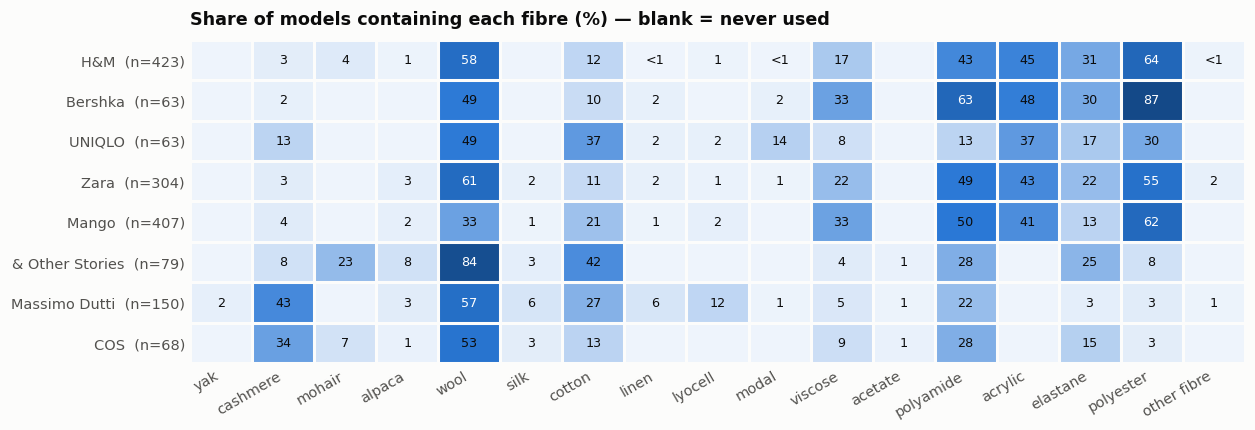

In [40]:
# prevalence: % of models whose main fabric contains each fibre
prev = comp.groupby("brand")[FIBERS].agg(lambda s: (s > 0).mean() * 100).loc[COMP_BRANDS]
prev = prev.loc[:, prev.max() > 0]
prev.columns = [{"other_animal_pct": "yak", "other_pct": "other fibre"}.get(c, c.replace("_pct", "")) for c in prev.columns]
fig, ax = plt.subplots(figsize=(11.5, 4.0))
heatmap(ax, prev, fmt=lambda v: "<1" if v < 0.5 else f"{v:.0f}", skip_zero=True)
ax.set_xticks(range(prev.shape[1]), prev.columns, rotation=30, ha="right")
ax.set_yticks(range(prev.shape[0]), [f"{b}  (n={(comp['brand'] == b).sum()})" for b in prev.index])
ax.set_title("Share of models containing each fibre (%) — blank = never used", pad=10)
fig.tight_layout()
savefig(fig, "fig_fiber_prevalence")
plt.show()

In [41]:
# dominant (largest) fibre of the main fabric, % of models per brand
dom = (pd.crosstab(comp["brand"], comp["dominant_fiber"], normalize="index") * 100).loc[COMP_BRANDS]
dom[dom.sum().sort_values(ascending=False).index].round(1)

dominant_fiber,wool,polyester,cotton,acrylic,viscose,cashmere,polyamide,mohair,modal,alpaca,silk,lyocell,linen,acetate,other_animal
brand,,,,,,,,,,,,,,,
H&M,13.5,53.2,6.4,9.7,12.5,1.2,3.1,0.2,0.0,0.2,0.0,0.0,0.0,0.0,0.0
Bershka,4.8,57.1,3.2,11.1,15.9,0.0,7.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
UNIQLO,19.0,1.6,27.0,34.9,1.6,11.1,0.0,0.0,4.8,0.0,0.0,0.0,0.0,0.0,0.0
Zara,16.8,30.9,5.3,22.0,16.4,2.6,5.3,0.0,0.0,0.0,0.0,0.7,0.0,0.0,0.0
Mango,5.4,26.5,16.2,21.6,22.1,2.2,4.9,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
& Other Stories,53.2,0.0,15.2,0.0,3.8,3.8,13.9,2.5,0.0,3.8,2.5,0.0,0.0,1.3,0.0
Massimo Dutti,54.7,0.0,21.3,0.0,2.7,16.7,0.0,0.0,0.7,1.3,0.7,0.0,1.3,0.0,0.7
COS,47.1,0.0,8.8,0.0,7.4,30.9,1.5,4.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [42]:
# segment level (UNIQLO shown separately because its prices sit with fast fashion)
comp_seg = comp.assign(group=np.where(comp["brand"].eq("UNIQLO"), "UNIQLO", comp["segment"]))
display(comp_seg.groupby("group")[["natural_pct", "wool_cashmere_pct", "synthetic_pct"]].agg(["mean", "median"]).round(1))
pd.DataFrame({v: mann_whitney(comp.loc[comp["segment"] == "Mid/premium", v], comp.loc[comp["segment"] == "Fast fashion", v])
              for v in ["natural_pct", "wool_cashmere_pct", "synthetic_pct"]}).T \
  .rename(columns={"n_a": "n_mid_premium", "n_b": "n_fast", "median_a": "median_mid_premium", "median_b": "median_fast"}).pipe(tidy)

natural_pct        wool_cashmere_pct        synthetic_pct       
                    mean median              mean median          mean median
group                                                                        
Fast fashion        24.6    5.0              15.4    4.0          61.8   77.0
Mid/premium         87.4  100.0              63.5   93.0           7.0    0.0
UNIQLO              57.8   53.0              35.3    8.0          33.3    4.0

,n_mid_premium,n_fast,median_mid_premium,median_fast,U,p,r_rb
natural_pct,360,1197,100.0,5.0,369950.0,2.9e-98,0.717
wool_cashmere_pct,360,1197,63.0,4.0,322285.0,1.7e-50,0.496
synthetic_pct,360,1197,0.0,77.0,64575.0,1.4e-92,-0.700


In [43]:
# same model, different colours: how different are the compositions?
vfm = vf.join(variants.set_index("variant_key")[["brand"]])
vfm["synthetic_pct"] = vfm[FIBER_GROUPS["Synthetic"]].sum(axis=1)
vfm["natural_pct"] = vfm[FIBER_GROUPS["Animal natural"] + FIBER_GROUPS["Plant natural"]].sum(axis=1)
rng_ = vfm.groupby("model_key").agg(brand=("brand", "first"), n=("brand", "size"),
                                    natural_range=("natural_pct", lambda s: s.max() - s.min()),
                                    synthetic_range=("synthetic_pct", lambda s: s.max() - s.min()))
rng_ = rng_[rng_["n"] > 1]
pd.DataFrame({"multi_colour_models_with_composition": rng_.groupby("brand").size(),
              "composition_differs": clean.groupby("brand")["composition_varies"].sum(),
              "natural_range_over_10pp": rng_.groupby("brand")["natural_range"].agg(lambda s: (s > 10).sum()),
              "max_natural_range_pp": rng_.groupby("brand")["natural_range"].max()}).reindex(COMP_BRANDS).fillna(0).round(1)

,multi_colour_models_with_composition,composition_differs,natural_range_over_10pp,max_natural_range_pp
brand,,,,
H&M,288,36,4,100.0
Bershka,51,2,1,59.0
UNIQLO,63,2,0,0.0
Zara,2,0,0,0.0
Mango,127,48,0,10.0
& Other Stories,56,0,0,0.0
Massimo Dutti,66,0,0,0.0
COS,39,1,0,1.0


**Reading:** fast fashion is mostly synthetic, mid/premium mostly natural.
- **H&M, Bershka, Zara, Mango:** synthetics make up 58–73 % of the average fabric; 55–78 % of models are synthetic-majority and only 6–20 % are fully natural. Two-thirds of fast-fashion models (66 %) contain less than 10 % natural fibre. **Bershka is the most synthetic** brand (73 % of the average fabric, 78 % synthetic-majority, polyester in 87 % of models).
- **Wool in small doses:** about half to 60 % of H&M, Bershka and Zara models contain wool or cashmere, but the median share when present is only 6–9 %. "Contains wool" is not the same as "wool sweater".
- **& Other Stories, Massimo Dutti, COS:** median 100 % natural, no synthetic-majority model, animal fibres 64–79 % of the average fabric. & Other Stories stands out for mohair (23 % of models) and wool (84 %); cashmere appears in 43 % of Massimo Dutti and 34 % of COS models.
- **UNIQLO** sits in between (median 53 % natural, 37 % synthetic-majority); when it uses wool or cashmere it is a large share (median 65 %).
- **Mango** uses the most man-made cellulosic fibre (18 % of the average fabric, mainly viscose).

Mid/premium vs fast fashion on natural share: r_rb = 0.72.

### 9. Price × fibre composition

Pooled correlations mix differences **between** brands and differences **within** a brand. Both are shown; the within-brand
numbers are the cleaner description of "does a higher natural share cost more?".

In [44]:
pairs = ["natural_pct", "wool_cashmere_pct", "animal_pct", "synthetic_pct", "cellulosic_pct"]
cp = comp.dropna(subset=["price"])
hm_regular = cp[(cp["brand"] == "H&M") & ~cp["subcategory"].eq("premium selection")]
scopes = [("pooled", cp)] + [(b, cp[cp["brand"] == b]) for b in COMP_BRANDS] + [("H&M regular line", hm_regular)]
rows = []
for scope, g in scopes:
    for v in pairs:
        if g[v].nunique() < 2:
            continue
        rho, p = stats.spearmanr(g["price"], g[v])
        rows.append({"scope": scope, "variable": v, "n": len(g), "rho": rho, "p": p})
corr = pd.DataFrame(rows)
corr["p_BH"] = bh(corr["p"])
corr_wide = corr.pivot(index="scope", columns="variable", values="rho").loc[[sc for sc, _ in scopes], pairs]
corr_wide.insert(0, "n", corr.groupby("scope")["n"].first())
display(corr_wide.round(2))
tidy(corr)

variable,n,natural_pct,wool_cashmere_pct,animal_pct,synthetic_pct,cellulosic_pct
scope,,,,,,
pooled,1557,0.53,0.46,0.49,-0.53,-0.17
H&M,423,0.47,0.47,0.47,-0.34,-0.27
Bershka,63,0.11,0.28,0.28,0.13,-0.27
UNIQLO,63,0.32,0.53,0.53,-0.27,-0.37
Zara,304,0.45,0.45,0.45,-0.24,-0.38
Mango,407,0.18,0.36,0.35,0.00,-0.23
& Other Stories,79,0.02,0.34,0.49,0.03,-0.06
Massimo Dutti,150,0.37,0.41,0.47,-0.32,-0.34
COS,68,0.42,0.48,0.49,-0.37,-0.35


,scope,variable,n,rho,p,p_BH
0,pooled,natural_pct,1557,0.534,2.1e-115,1.0e-113
1,pooled,wool_cashmere_pct,1557,0.459,7.8e-82,9.8e-81
2,pooled,animal_pct,1557,0.486,5.2e-93,8.7e-92
3,pooled,synthetic_pct,1557,-0.525,4.4e-111,1.1e-109
4,pooled,cellulosic_pct,1557,-0.174,4.2e-12,1.5e-11
5,H&M,natural_pct,423,0.466,3.0e-24,2.2e-23
6,H&M,wool_cashmere_pct,423,0.466,3.1e-24,2.2e-23
7,H&M,animal_pct,423,0.467,2.5e-24,2.2e-23
8,H&M,synthetic_pct,423,-0.341,5.2e-13,2.0e-12
9,H&M,cellulosic_pct,423,-0.266,2.9e-08,8.6e-08


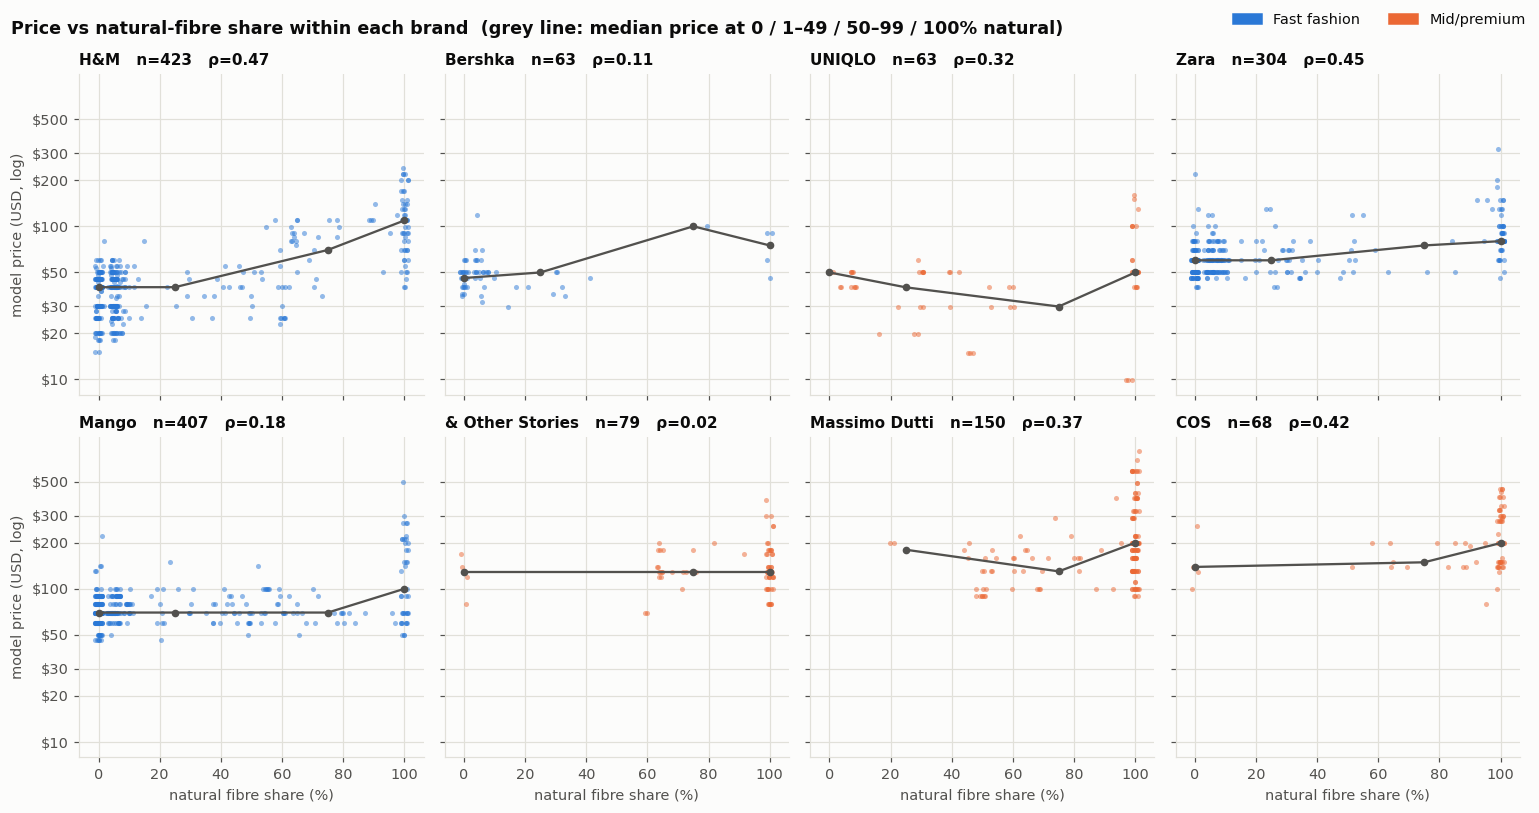

In [45]:
ncol = 4
nrow = int(np.ceil(len(COMP_BRANDS) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3.4 * nrow + 0.6), sharex=True, sharey=True)
for ax in axes.flat[len(COMP_BRANDS):]:
    ax.set_visible(False)
for ax, b in zip(axes.flat, COMP_BRANDS):
    g = cp[cp["brand"] == b]
    col = SEG_COLORS[SEGMENT[b]]
    ax.scatter(g["natural_pct"] + rng.uniform(-1.2, 1.2, len(g)), g["price"], s=11, color=col, alpha=0.5, linewidths=0)
    med = g.groupby(pd.cut(g["natural_pct"], [-1, 0, 49.99, 99.49, 100.1], labels=[0, 25, 75, 100]), observed=True)["price"].median()
    ax.plot(med.index.astype(float), med.values, color=INK2, linewidth=1.5, marker="o", markersize=4, zorder=4)
    rho = corr[(corr["scope"] == b) & (corr["variable"] == "natural_pct")]["rho"]
    ax.set_title(f"{b}   n={len(g)}   ρ={rho.iloc[0]:.2f}" if len(rho) else f"{b}   n={len(g)}", fontsize=10)
    ax.set_yscale("log")
    usd_axis(ax, "y")
for ax in axes[-1]:
    ax.set_xlabel("natural fibre share (%)")
for ax in axes[:, 0]:
    ax.set_ylabel("model price (USD, log)")
fig.suptitle("Price vs natural-fibre share within each brand  (grey line: median price at 0 / 1–49 / 50–99 / 100% natural)",
             x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.legend(handles=[Patch(color=c, label=s) for s, c in SEG_COLORS.items()], loc="upper right", ncol=2, frameon=False)
fig.tight_layout()
savefig(fig, "fig_price_vs_natural")
plt.show()

In [46]:
# median price by natural-share band (n in brackets)
band = pd.cut(cp["natural_pct"], [-1, 0, 49.99, 99.49, 100.1], labels=["0%", "1–49%", "50–99%", "100%"])
med = cp.groupby(["brand", band], observed=False)["price"].median().unstack()
cnt = cp.groupby(["brand", band], observed=False)["price"].size().unstack()
(med.round(0).astype("Int64").astype(str) + " (" + cnt.astype(str) + ")").where(cnt > 0, "–").loc[COMP_BRANDS]

natural_pct,0%,1–49%,50–99%,100%
brand,,,,
H&M,40 (124),40 (196),70 (51),109 (52)
Bershka,46 (26),50 (32),100 (1),75 (4)
UNIQLO,50 (2),40 (29),30 (9),50 (23)
Zara,60 (85),60 (142),75 (16),80 (61)
Mango,70 (174),70 (140),70 (49),100 (44)
& Other Stories,129 (4),–,129 (23),129 (52)
Massimo Dutti,–,180 (7),130 (40),200 (103)
COS,139 (5),–,149 (17),199 (46)


**Reading:** the clearest within-brand pattern is for **animal fibres**: ρ(price, animal share) is positive and significant after BH correction in all eight brands (0.28–0.53). Total natural share works less well, because cotton is natural but not expensive: at & Other Stories mostly-cotton models have a median price of $79, mostly-animal-fibre models $129 (mohair blends $134), so ρ(price, natural share) ≈ 0 there, and it is also weak in Bershka (0.11, n.s.) and Mango (0.18). In H&M, Zara, Massimo Dutti and COS it is 0.37–0.47. Three qualifications:
1. The relation is mostly a **step at 100 % natural**, not a steady slope: Mango's median price is $70 at 0 %, 1–49 % and 50–99 % natural and $100 at 100 %; Zara goes from $60 to $80.
2. At H&M it comes entirely from the Premium Selection line; inside the regular line ρ ≈ 0 (natural 0.06, wool + cashmere 0.03, both n.s.).
3. & Other Stories prices barely move with fibre: the median is $129 in every natural-share band.

The pooled correlation (ρ = 0.53) mixes between-brand and within-brand differences, so later models should include brand.

### 10. Country of origin

In [47]:
pd.crosstab(clean["brand"], clean["origin_status"], margins=True).loc[BRAND_ORDER + ["All"]]

origin_status,'Imported' only,country given,not available,All
brand,,,,
H&M,0,0,423,423
Bershka,0,63,2,65
UNIQLO,62,1,0,63
Zara,0,0,304,304
Mango,0,407,0,407
& Other Stories,0,0,80,80
Massimo Dutti,0,146,6,152
COS,0,68,0,68
All,62,685,815,1562


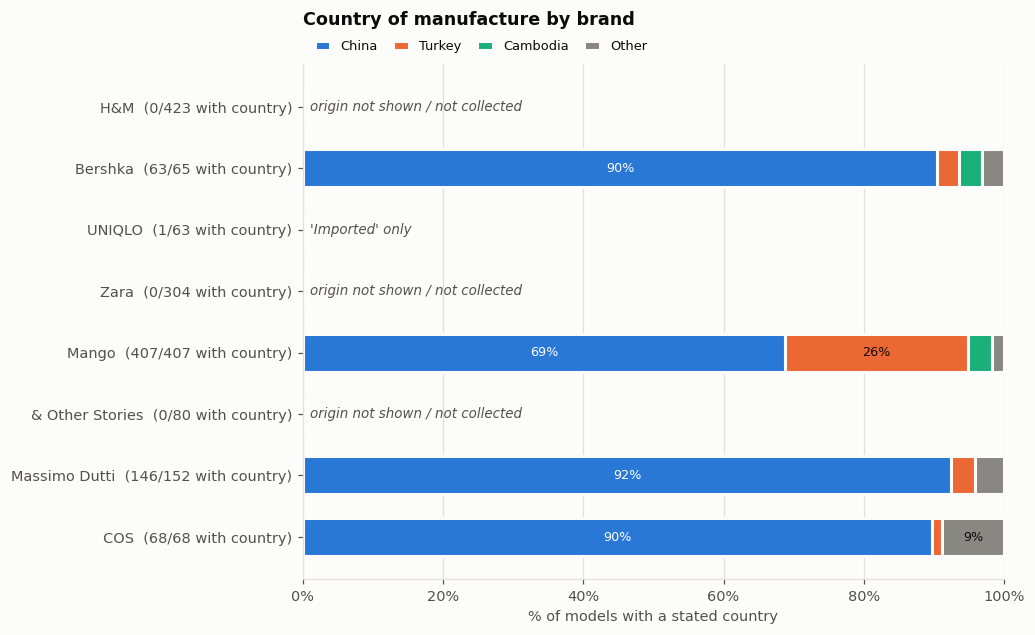

origin_country_std,Bangladesh,Cambodia,China,Italy,Japan,Spain,Turkey,Vietnam,All
brand,,,,,,,,,
Bershka,2,2,57,0,0,0,2,0,63
COS,0,0,61,0,0,1,1,5,68
Mango,6,14,280,0,0,0,106,1,407
Massimo Dutti,0,0,135,3,0,3,5,0,146
UNIQLO,0,0,0,0,1,0,0,0,1
All,8,16,533,3,1,4,114,6,685


In [48]:
orig = clean[clean["origin_status"] == "country given"]
top = ["China", "Turkey", "Cambodia"]
oc = orig["origin_country_std"].where(orig["origin_country_std"].isin(top), "Other")
n_o = orig["brand"].value_counts()
enough = n_o[n_o >= 10].index                      # a share needs at least 10 models behind it
oshare = (pd.crosstab(orig["brand"], oc, normalize="index") * 100).reindex(columns=top + ["Other"])
oshare.loc[~oshare.index.isin(enough)] = np.nan
oshare = oshare.reindex(BRAND_ORDER)
labels = [f"{b}  ({n_o.get(b, 0)}/{n_mod[b]} with country)" for b in BRAND_ORDER]
status = clean.groupby("brand")["origin_status"].agg(lambda s: s.value_counts().index[0])
notes = {b: ("'Imported' only" if status[b] == "'Imported' only" else "origin not shown / not collected")
         for b in BRAND_ORDER if b not in enough}
fig, ax = stacked_bars(oshare, {"China": BLUE, "Turkey": ORANGE, "Cambodia": AQUA, "Other": NEUTRAL}, labels, notes=notes,
                       xlabel="% of models with a stated country", title="Country of manufacture by brand", fname="fig_origin")
plt.show()
pd.crosstab(orig["brand"], orig["origin_country_std"], margins=True)

In [49]:
# Mango lists separate production stages: are dyeing and weaving done in the same country as manufacturing?
mg = clean[clean["brand"] == "Mango"]
print("Mango models -> manufacture stated:", mg["origin_manufacture"].notna().sum(), "| weave stated:", mg["origin_weave"].notna().sum())
display(pd.crosstab(mg["origin_manufacture"], mg["origin_weave"].fillna("not stated"), margins=True))
# price and fibre by country, brands with a stated country
orig.groupby(["brand", "origin_country_std"]).agg(n=("brand", "size"), median_price=("price", "median"),
                                                  mean_natural_pct=("natural_pct", "mean"),
                                                  mean_synthetic_pct=("synthetic_pct", "mean")).query("n >= 5").round(1)

Mango models -> manufacture stated: 407 | weave stated: 337


origin_weave,Bangladesh,China,Turkey,not stated,All
origin_manufacture,,,,,
Bangladesh,2,0,0,4,6
Cambodia,0,13,0,1,14
China,0,270,0,10,280
Turkey,0,1,51,54,106
Vietnam,0,0,0,1,1
All,2,284,51,70,407


n  median_price  mean_natural_pct  mean_synthetic_pct
brand         origin_country_std                                                         
Bershka       China                57          49.9              11.1                76.1
COS           China                61         199.0              87.8                 7.0
              Vietnam               5         279.0             100.0                 0.0
Mango         Bangladesh            6          55.0               0.0                30.8
              Cambodia             14          60.0              35.0                53.4
              China               280          70.0              26.1                56.2
              Turkey              106          80.0              14.1                67.7
Massimo Dutti China               135         180.0              89.0                 4.3
              Turkey                5         130.0              78.8                 8.8

**Reading:** a country is now stated for Bershka (63/65), Mango (407/407), Massimo Dutti (146/152) and COS (68/68). It is not shown or not collected for Zara, H&M and & Other Stories, and UNIQLO only says "Imported". Where known, production is concentrated in China (78 % of 685 models) and Turkey (17 %). China dominates every brand with data (90–92 % at Bershka, Massimo Dutti and COS) except Mango, which makes 26 % of its models in Turkey. So the price segment does **not** map to a different production country: the mid/premium Massimo Dutti and COS are as China-made as the fast-fashion Bershka. Mango's stage detail: when the weaving country is given it is the manufacturing country, except Cambodia-made models, whose fabric is woven in China (13 of 14). Inside Mango, Turkey-made models are more synthetic (68 % vs 56 % for China-made) and have a higher median price ($80 vs $70).

→ Origin is usable only for these four brands (two fast fashion, two mid/premium).

### 11. Sustainability claims

A claim is counted when the product page states recycled content, a certification (RWS, RCS, RMS, RAS, GCS, OCS, GOTS, GRS…) or organic fibre.
A model counts as claiming if any of its colours does. Where the claim was found differs by brand, so **coverage is part of the result**:
for H&M no field carrying claims was captured, which means "not observed", not "no claim".

In [50]:
sust = clean.groupby("brand").agg(
    claim_source=("claim_source", "first"), models=("brand", "size"), observable=("claim_observable", "sum"),
    recycled=("recycled_claim", "sum"), certified=("certified_claim", "sum"), organic=("organic_claim", "sum"),
    any_claim=("any_claim", "sum"), median_recycled_pct_if_claim=("recycled_pct", lambda s: s[s > 0].median()),
).loc[BRAND_ORDER]
for c in ["recycled", "certified", "organic", "any_claim"]:
    sust[f"{c}_pct"] = (sust[c] / sust["observable"].replace(0, np.nan) * 100).round(1)
sust

,claim_source,models,observable,recycled,certified,organic,any_claim,median_recycled_pct_if_claim,recycled_pct,certified_pct,organic_pct,any_claim_pct
brand,,,,,,,,,,,,
H&M,none captured,423,0,0,0,0,0,NaN,<NA>,<NA>,<NA>,<NA>
Bershka,sustainability field,65,63,42,44,0,44,87.0,66.7,69.8,0.0,69.8
UNIQLO,sustainability field,63,63,10,0,0,10,32.0,15.9,0.0,0.0,15.9
Zara,sustainability field,304,304,203,226,4,226,96.0,66.8,74.3,1.3,74.3
Mango,composition text,407,407,9,0,0,9,42.0,2.2,0.0,0.0,2.2
& Other Stories,sustainability field,80,80,12,67,0,72,33.0,15.0,83.8,0.0,90.0
Massimo Dutti,sustainability field,152,150,70,121,34,121,70.0,46.7,80.7,22.7,80.7
COS,description,68,68,5,8,0,10,20.5,7.4,11.8,0.0,14.7


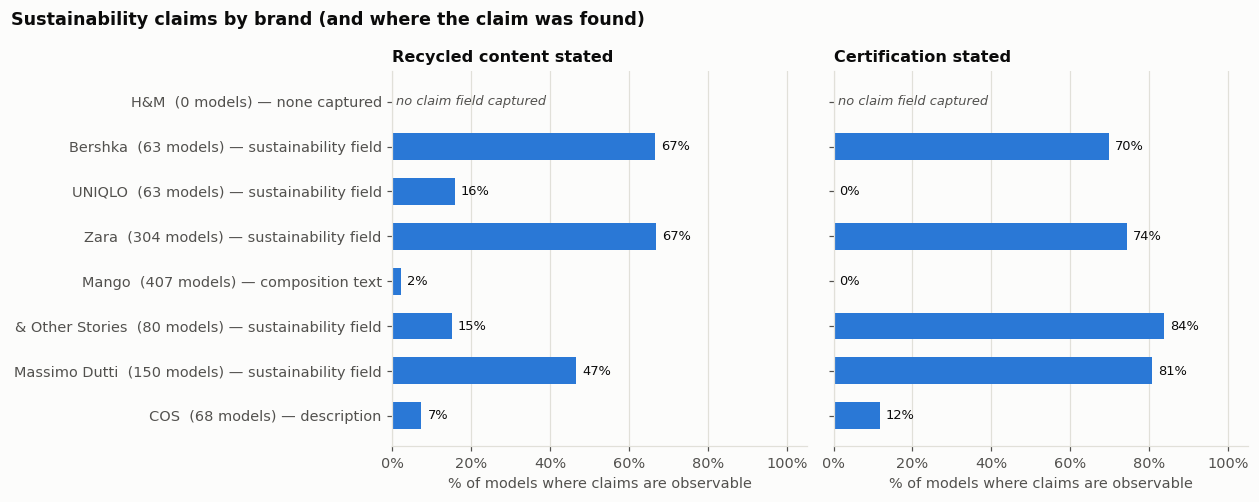

In [51]:
obs = clean[clean["claim_observable"]]
rates = obs.groupby("brand")[["recycled_claim", "certified_claim"]].mean().mul(100).reindex(BRAND_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=True)
ypos = np.arange(len(BRAND_ORDER))[::-1]
for ax, col, title in zip(axes, ["recycled_claim", "certified_claim"], ["Recycled content stated", "Certification stated"]):
    vals = rates[col]
    ax.barh(ypos, vals.fillna(0), color=BLUE, height=0.6)
    for yi, b in zip(ypos, BRAND_ORDER):
        v = vals[b]
        if pd.isna(v):
            ax.text(1, yi, "no claim field captured", va="center", fontsize=8.5, color=INK2, style="italic")
        else:
            ax.text(v + 1.5, yi, f"{v:.0f}%", va="center", fontsize=8.5, color=INK)
    ax.set_xlim(0, 105)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_title(title, fontsize=10.5)
    ax.set_xlabel("% of models where claims are observable")
n_obs = obs["brand"].value_counts()
axes[0].set_yticks(ypos, [f"{b}  ({n_obs.get(b, 0)} models) — {CLAIM_SOURCE[b]}" for b in BRAND_ORDER])
fig.suptitle("Sustainability claims by brand (and where the claim was found)", x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.tight_layout()
savefig(fig, "fig_sustainability")
plt.show()

In [52]:
# which certifications / recycled fibres appear in the dedicated sustainability fields (variant level, unique per model)
uniq = variants.drop_duplicates(["model_key", "sustainability_raw"])
terms = uniq["sustainability_raw"].str.upper().str.findall(
    r"\bRWS\b|\bRCS\b|\bOCS\b|\bRMS\b|\bRAS\b|\bGCS\b|\bGOTS\b|\bGRS\b|RECYCLED [A-Z]+|ORGANIC[A-Z ]*COTTON|EUROPEAN GROWN LINEN|USES RECYCLED [A-Z]+")
(terms.explode().dropna().str.replace(r"ORGANIC.*COTTON", "ORGANIC COTTON", regex=True).str.replace("USES ", "")
     .groupby(uniq["brand"]).value_counts().unstack(0).fillna(0).astype(int)
     .pipe(lambda t: t.loc[t.sum(axis=1).sort_values(ascending=False).index]))

brand,& Other Stories,Bershka,Massimo Dutti,UNIQLO,Zara
sustainability_raw,,,,,
RCS,0,103,80,0,432
RECYCLED POLYESTER,2,37,4,11,124
RECYCLED POLYAMIDE,12,31,27,0,106
RWS,64,2,43,0,52
RECYCLED WOOL,0,11,38,0,77
RECYCLED ACRYLIC,0,22,0,0,89
OCS,0,0,36,0,4
ORGANIC COTTON,0,0,35,0,4
RECYCLED COTTON,0,1,3,0,26


In [53]:
# how much of the synthetic-heavy knitwear is declared recycled? (brands with a dedicated sustainability field)
sf = obs[obs["claim_source"].eq("sustainability field") & obs["has_composition"]]
display(sf.groupby(["brand", "synthetic_majority"]).agg(
    n=("brand", "size"), pct_recycled_claim=("recycled_claim", "mean"),
    median_recycled_pct=("recycled_pct", "median"), mean_synthetic_pct=("synthetic_pct", "mean")).round(2))

# do claimed models differ in price or fibre mix? (within brand)
rows = []
for b in [b for b in BRAND_ORDER if b in obs["brand"].unique()]:
    g = obs[obs["brand"] == b]
    yes, no = g["any_claim"].fillna(False).astype(bool), ~g["any_claim"].fillna(False).astype(bool)
    if yes.sum() < 5 or no.sum() < 5:
        continue
    r = mann_whitney(g.loc[yes, "price"], g.loc[no, "price"])
    rows.append({"brand": b, "n_claim": r["n_a"], "n_no_claim": r["n_b"], "median_price_claim": r["median_a"],
                 "median_price_no_claim": r["median_b"], "p": r["p"],
                 "mean_natural_claim": g.loc[yes, "natural_pct"].mean(), "mean_natural_no_claim": g.loc[no, "natural_pct"].mean()})
tidy(pd.DataFrame(rows).set_index("brand"))

n  pct_recycled_claim  median_recycled_pct  mean_synthetic_pct
brand           synthetic_majority                                                                  
& Other Stories False                79                0.14                  0.0               10.38
Bershka         False                14                0.43                  0.0               26.93
                True                 49                0.73                 76.0               86.45
Massimo Dutti   False               150                0.47                  0.0                5.35
UNIQLO          False                40                 0.1                  0.0                5.68
                True                 23                0.26                  0.0               81.22
Zara            False               127                0.52                 25.0               15.19
                True                177                0.77                 91.0               87.90

,n_claim,n_no_claim,median_price_claim,median_price_no_claim,p,mean_natural_claim,mean_natural_no_claim
brand,,,,,,,
Bershka,44,19,49.90,49.90,0.551,12.136,17.237
UNIQLO,10,53,44.90,49.90,0.969,15.700,65.774
Zara,226,78,59.90,59.90,1.8e-04,34.814,14.641
Mango,9,398,69.99,69.99,0.219,7.444,23.188
& Other Stories,72,8,129.00,89.00,0.009,86.887,75.000
Massimo Dutti,121,29,160.00,390.00,3.4e-10,87.967,88.897
COS,10,58,284.50,194.00,0.066,84.100,88.164


**Reading:** claims can now be observed for 7 of 8 brands (all but H&M), and the two segments claim different things.
- **Fast fashion claims are about recycled synthetics.** Zara: 74 % of models certified and 67 % with recycled content; Bershka: 70 % certified (mostly RCS) and 67 % recycled. 77 % of Zara's and 73 % of Bershka's synthetic-majority models declare recycled fibres (median 91 % and 76 % recycled).
- **Mid/premium claims are about certified animal fibres.** & Other Stories: 84 % certified (RWS wool, RMS mohair, RAS alpaca, GCS cashmere); Massimo Dutti: 81 % certified (RWS, RCS, OCS organic cotton in 23 % of models).
- Any claim: **UNIQLO 16 %** (recycled polyester only), **COS 15 %** and **Mango 2 %** — the last two come from free text (description, composition note), so they are lower bounds.
- **H&M:** no field carrying claims was captured, so it cannot be compared.

Price: claimed and unclaimed models have the same median price at Zara, Bershka, Mango and UNIQLO. At Massimo Dutti claimed models are cheaper ($160 vs $390) because most unclaimed ones are cashmere (21 of 29); at & Other Stories claimed ones are pricier ($129 vs $89), but only 8 models are unclaimed.

### 12. Care instructions

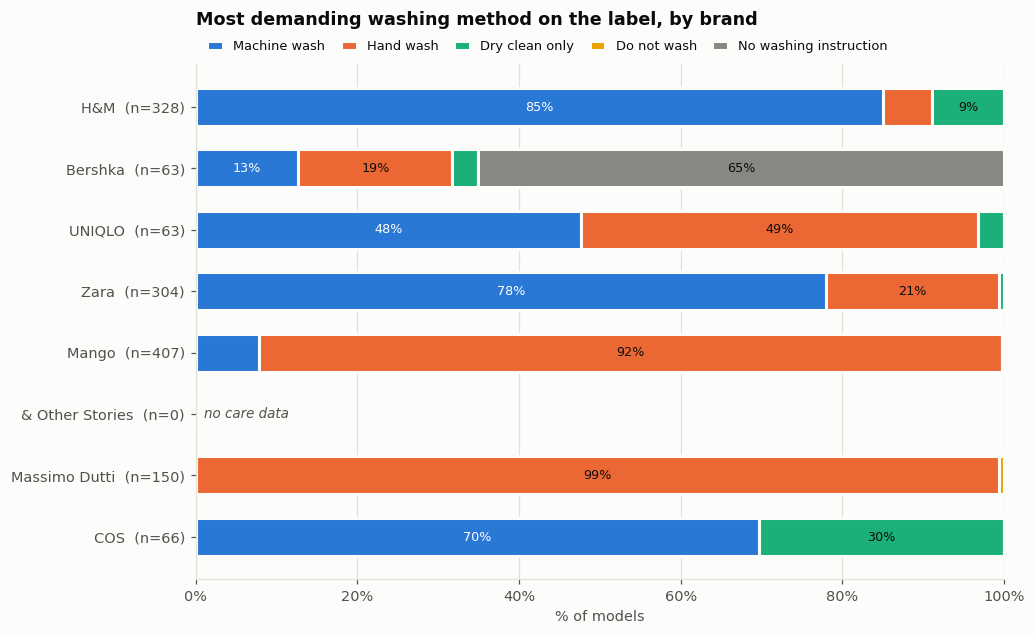

care_category,Machine wash,Hand wash,Dry clean only,Do not wash,No washing instruction
brand,,,,,
H&M,85.1,6.1,8.8,0.0,0.0
Bershka,12.7,19.0,3.2,0.0,65.1
UNIQLO,47.6,49.2,3.2,0.0,0.0
Zara,78.0,21.4,0.7,0.0,0.0
Mango,7.9,91.9,0.0,0.0,0.2
& Other Stories,NaN,NaN,NaN,NaN,NaN
Massimo Dutti,0.0,99.3,0.0,0.7,0.0
COS,69.7,0.0,30.3,0.0,0.0


,natural_pct,wool_cashmere_pct,synthetic_pct
care_category,,,
Machine wash,24.1,13.6,62.7
Hand wash,46.6,32.8,40.6
Dry clean only,86.4,73.4,12.7
Do not wash,100.0,100.0,0.0
No washing instruction,7.7,4.9,76.2


In [54]:
care = clean.dropna(subset=["care_category"])
CARE_ORDER = [c for c in ["Machine wash", "Hand wash", "Dry clean only", "Do not wash", "No washing instruction"]
              if c in set(care["care_category"])]
cshare = (pd.crosstab(care["brand"], care["care_category"], normalize="index") * 100).reindex(columns=CARE_ORDER).reindex(BRAND_ORDER)
n_c = care["brand"].value_counts()
labels = [f"{b}  (n={n_c.get(b, 0)})" for b in BRAND_ORDER]
notes = {b: "no care data" for b in BRAND_ORDER if b not in n_c.index}
palette = dict(zip(["Machine wash", "Hand wash", "Dry clean only", "Do not wash"], [BLUE, ORANGE, AQUA, YELLOW]))
palette["No washing instruction"] = NEUTRAL
fig, ax = stacked_bars(cshare, {c: palette[c] for c in CARE_ORDER}, labels, notes=notes,
                       title="Most demanding washing method on the label, by brand", fname="fig_care")
plt.show()
display(cshare.round(1))
care.groupby("care_category")[["natural_pct", "wool_cashmere_pct", "synthetic_pct"]].mean().reindex(CARE_ORDER).round(1)

**Reading:** care labels follow the brand more than the fibre. Mango labels 92 % of its models hand-wash although 59 % of its average fabric is synthetic, and Massimo Dutti 99 %, while H&M (85 %) and Zara (78 %) mostly allow machine washing. "Dry clean only" is rare except at COS (30 %) and goes with natural fibres (86 % natural on average). **Bershka lists no washing instruction at all for 65 % of its models** (only bleach / iron / dry-clean / tumble-dry symbols — the same as on the page checked during scraping), and & Other Stories shows no care data. Care is a brand convention rather than a clean proxy for fibre quality.

#### 13. Some Correlations (Spearman)

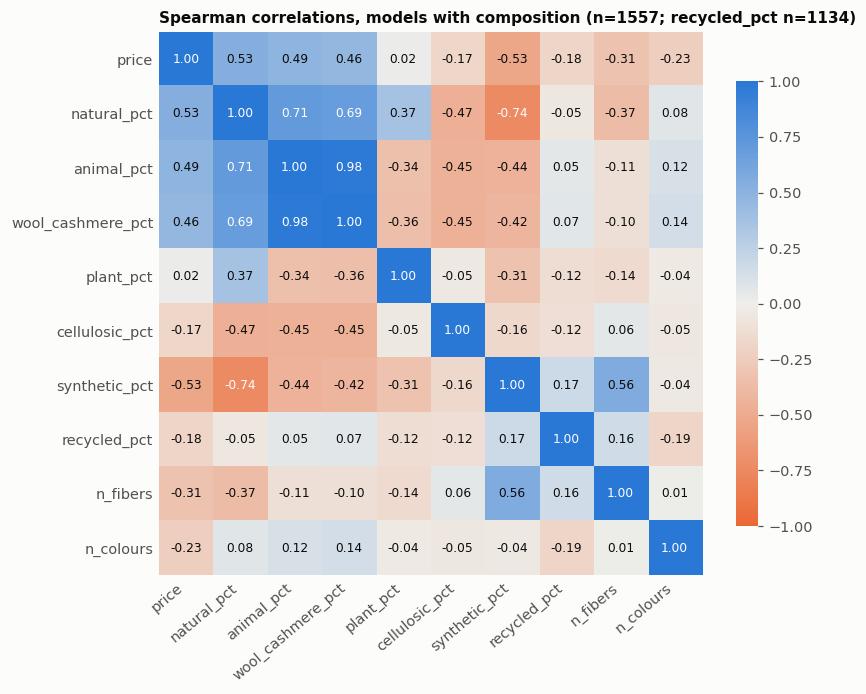

In [55]:
CV = ["price", "natural_pct", "animal_pct", "wool_cashmere_pct", "plant_pct", "cellulosic_pct", "synthetic_pct",
      "recycled_pct", "n_fibers", "n_colours"]
rho = comp[CV].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.8, 6.6))
im = ax.imshow(rho.to_numpy(), cmap=DIV, vmin=-1, vmax=1)
for i in range(len(CV)):
    for j in range(len(CV)):
        v = rho.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else INK)
ax.set_xticks(range(len(CV)), CV, rotation=40, ha="right")
ax.set_yticks(range(len(CV)), CV)
ax.grid(False)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.75)
cb.outline.set_visible(False)
ax.set_title(f"Spearman correlations, models with composition (n={len(comp)}; recycled_pct n={comp['recycled_pct'].notna().sum()})", fontsize=10)
fig.tight_layout()
savefig(fig, "fig_spearman")
plt.show()

**Reading:** pooled over brands (n = 1,557 models), price correlates as strongly with natural share (+0.53) as negatively with synthetic share (−0.53). Plant fibres (cotton, linen) do not move price (+0.02); the premium is for animal fibres (+0.49). Blends with more fibres are cheaper (−0.31) and more synthetic (+0.56). Cheaper models come in more colours (−0.23), mostly a between-brand effect (H&M and UNIQLO list many colours). `recycled_pct` is only defined where claims are observable, so its correlations mostly reflect Zara and Bershka.

---
## 14. Summary of findings and limitations

**Data after cleaning:** 1,562 in-scope models (3,169 colour variants) from 8 brands; 36 knit tops removed, 7 capes kept and flagged. Composition is available for 1,557 models (99.7 %); the parser reproduced the scrapers' 3,143 parsed variants exactly and recovered 20 more.

| Topic | Main result | How solid |
|---|---|---|
| Price by brand | Medians $40 (H&M) to $199 (COS); brand explains much of price (ε² = 0.60). & Other Stories, Massimo Dutti and COS form a separate tier ($129–199); UNIQLO ($50) is priced like fast fashion. | Solid; unchanged with regular prices |
| Fibre mix | Fast fashion (H&M, Bershka, Zara, Mango): 58–73 % synthetic, 55–78 % synthetic-majority, 66 % of models < 10 % natural; Bershka most synthetic. & Other Stories / Massimo Dutti / COS: median 100 % natural, no synthetic-majority model. | Solid, all 8 brands covered |
| Wool in fast fashion | About half to 60 % of H&M, Bershka and Zara models contain wool, typically 6–9 % of the fabric. | Solid |
| Price × fibre | Animal-fibre share goes with price inside all 8 brands (ρ 0.28–0.53); total natural share less so (cotton is cheap). Mostly a step at 100 % natural; H&M's relation is the Premium Selection line; & Other Stories prices barely vary. | Descriptive (no controls yet) |
| Origin | China 78 %, Turkey 17 % where stated (Bershka, Mango, Massimo Dutti, COS). Mid/premium is as China-made as fast fashion; Mango is the Turkey exception. | 4 of 8 brands |
| Sustainability | Fast fashion claims recycled synthetics (Zara, Bershka ~67 % recycled, ~70–74 % certified); mid/premium claims certified animal fibres (& Other Stories 84 %, Massimo Dutti 81 % certified). | 7 of 8 brands; Mango / COS lower bounds; H&M not observed |
| Care | Brand convention (Mango, Massimo Dutti hand wash; H&M, Zara machine wash); Bershka mostly gives no washing instruction. | Weakly linked to fibre |

**Limitations to carry into the research questions**
1. **No ultra-fast segment:** SHEIN has no data.
2. **Brand-specific gaps:** origin missing for Zara, H&M and & Other Stories (UNIQLO only "Imported"); care missing for & Other Stories; sustainability not captured for H&M.
3. **Saved-page brands** (H&M, UNIQLO, COS, & Other Stories) cover the listing pages that were saved, not necessarily the full catalogue.
4. **Unequal colour sampling:** Zara ≈ 1 colour per model, UNIQLO ≈ 5 — hence the model is the unit of analysis.
5. **Snapshot of 22–26 Oct 2026:** H&M had 14.5 % of colours on sale; UNIQLO's sale items have no original price.
6. **Absence of a claim ≠ absence of a practice:** claims depend on what each page shows and where it was scraped from.
7. **Segment label vs price:** UNIQLO's segment does not match its prices; segment results should be shown with and without UNIQLO.

**Implications for the next part (research questions)**
- Use **log price** and rank-based / robust methods; include **brand** (or within-brand comparisons) when relating price to fibre.
- Separate **animal fibres** from plant fibres: the price premium is for wool, cashmere, mohair and alpaca, not for natural fibre as such.
- Treat H&M Premium Selection as a separate line (or a control) and UNIQLO as its own group.
- Restrict origin questions to the four brands with a stated country, and sustainability questions to the seven brands where claims are observable.